# C1 – Week 2: Museum painting retrieval with spatial colour histograms and background removal

**Team 4 · Master in Computer Vision (C1)**

This notebook contains everything we did for week 2: the code, the experiments, the reasons behind every decision and the
conclusions. Each experiment follows the same structure: **Why** (what we want to find out), **Result** (the numbers or the
figure) and **Conclusion** (what we keep).

| Task | What is asked | Section |
|---|---|---|
| 1 | Implement 3D / 2D, block and hierarchical (spatial pyramid) histograms | §2 (implementation, visualisations) and §3 (experiments) |
| 2 | Evaluate the best descriptor on QSD1-W2 and compare it with the best one of week 1 | §6.3 (final methods in §6.2) |
| 3 | Remove the background of the QSD2 images **using only colour**, and build a binary mask | §4 |
| 4 | Evaluate the masks with precision, recall and F1 | §5 |
| 5 | QSD2: remove the background, retrieve, and evaluate the retrieval | §6 (and §6.1: robustness to imperfect masks) |
| 6 | Generate the blind-test submission for QST1 and QST2 (top-10 lists + masks) | §7 (also `run_w2.py`) |

A summary of all the results, ready for the slides, is in **§8**.

**Data**
- `BBDD/` (in `../week1/`): the museum database, 287 paintings `bbdd_XXXXX.jpg`. The id is the number in the file name.
- `qsd1_w2/qsd1_w1/`: 30 cropped queries, one painting per image. **It is the same set as QSD1-W1**, so the comparison with week 1 is direct.
- `qsd2_w2/qsd2_w1/`: 30 photos of a painting hanging on the wall (with background), the ground-truth masks (`.png`) and `gt_corresps.pkl`.
- QST1 / QST2: the blind test sets (no ground truth). They are published on Thursday 15 Oct at 14:00.

**How to run.** Put this notebook in `Project/week2/`, next to `qsd1_w2/` and `qsd2_w2/` (the BBDD is read from
`../week1/BBDD`). It needs `opencv-python`, `numpy`, `pandas` and `matplotlib` (`scikit-learn` only for one optional
experiment). It runs all the experiments again, so it takes a while. The figures for the slides are also saved in
`figures/`.

## 0. Setup

In [1]:
import pickle
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=3, suppress=True)
try:
    display                     # defined inside Jupyter
except NameError:
    display = print


def find_dir(*candidates, pattern="*.jpg"):
    """Return the first folder (or a sub-folder one level down) that contains images matching `pattern`."""
    for c in map(Path, candidates):
        if c.is_dir():
            if any(c.glob(pattern)):
                return c
            for sub in sorted(p for p in c.iterdir() if p.is_dir()):
                if any(sub.glob(pattern)):
                    return sub
    return None


BBDD_DIR = find_dir("../week1/BBDD", "BBDD", pattern="bbdd_*.jpg")
QSD1_DIR = find_dir("qsd1_w2", "qsd1_w1")
QSD2_DIR = find_dir("qsd2_w2", "qsd2_w1")
QST1_DIR = find_dir("qst1_w2", "qst1_w2/qst1_w2")   # blind test sets (None until they are published)
QST2_DIR = find_dir("qst2_w2", "qst2_w2/qst2_w2")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results")

MAX_SIDE = 512   # every image is resized so that its longest side is 512 px (same as week 1)
EPS = 1e-10
K = 10           # results per query in the submission

# plot style: the colours of the course slide template
TEAL, ORANGE, GREY, RED = "#1B7F79", "#F0A830", "#9AA5AB", "#C8553D"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10})


def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png")


print("BBDD:", BBDD_DIR, "| QSD1:", QSD1_DIR, "| QSD2:", QSD2_DIR, "| QST1:", QST1_DIR, "| QST2:", QST2_DIR)

BBDD: ../week1/BBDD | QSD1: qsd1_w2 | QSD2: qsd2_w2 | QST1: None | QST2: None


## 1. Data

We load every image once and resize it (longest side 512 px). For QSD2 we also keep the full-resolution image, because
the masks must be computed and evaluated at the original size.

In [2]:
def image_id(path):
    """'bbdd_00120.jpg' -> 120, '00007.jpg' -> 7"""
    return int(Path(path).stem.split("_")[-1])


def resize_max(img, max_side=MAX_SIDE):
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img


def load_folder(folder, pattern="*.jpg", max_side=MAX_SIDE):
    paths = sorted(Path(folder).glob(pattern), key=image_id)
    return [image_id(p) for p in paths], [resize_max(cv2.imread(str(p)), max_side) for p in paths]


def load_gt(folder):
    with open(Path(folder) / "gt_corresps.pkl", "rb") as f:
        return pickle.load(f)


t0 = time.time()
BBDD_IDS, BBDD = load_folder(BBDD_DIR, "bbdd_*.jpg")
QSD1_IDS, QSD1 = load_folder(QSD1_DIR)
QSD2_IDS, QSD2_FULL = load_folder(QSD2_DIR, max_side=100000)            # full resolution
QSD2_GTMASK = [cv2.imread(str(QSD2_DIR / f"{i:05d}.png"), 0) > 0 for i in QSD2_IDS]
GT1, GT2 = load_gt(QSD1_DIR), load_gt(QSD2_DIR)
print(f"{len(BBDD)} BBDD, {len(QSD1)} QSD1, {len(QSD2_FULL)} QSD2 images loaded in {time.time() - t0:.0f}s")
print("QSD1 GT:", GT1[:6], "...")
print("QSD2 GT:", GT2[:6], "...   -> one painting per image, so the output is a list of lists")

287 BBDD, 30 QSD1, 30 QSD2 images loaded in 7s
QSD1 GT: [[120], [170], [277], [227], [251], [274]] ...
QSD2 GT: [[100], [219], [250], [25], [22], [215]] ...   -> one painting per image, so the output is a list of lists


**QSD2 with background.** Below, each QSD2 image with the outline of its ground-truth mask (red). Things we notice and
that will matter later:
- The painting is roughly centred on a **grey / beige wall**, sometimes with a small label next to it.
- The **GT mask includes the frame**, and the BBDD images also include the frame. So the bounding box of the mask gives
  almost the same picture as the BBDD image.
- Some paintings come **close to the image border** (5, 6, 11, 16, 23; at least 60 px of wall remain), some are slightly **rotated / in perspective** (14, 17, 25),
  and some are **white on a white wall** (20) or have a white passe-partout (29): these will be the hard cases.
- Some paintings cast a **shadow** on the wall below them.

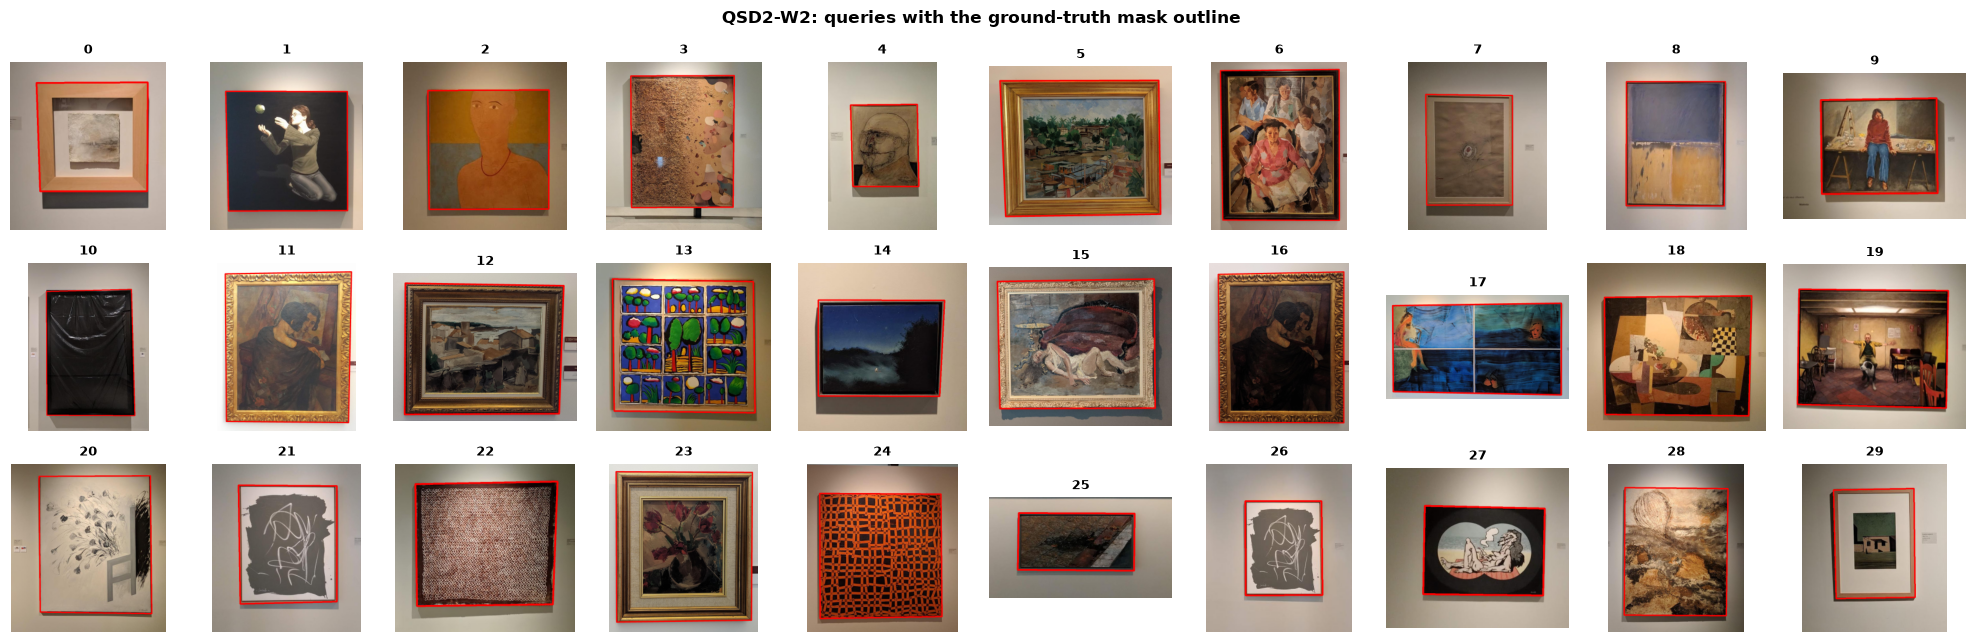

In [3]:
def outline(img, mask, color=(0, 0, 255), width=None):
    out = img.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # only for drawing
    cv2.drawContours(out, cnts, -1, color, width or max(2, img.shape[1] // 120))
    return out


fig, axes = plt.subplots(3, 10, figsize=(20, 6.5))
for ax, i in zip(axes.ravel(), range(30)):
    ax.imshow(resize_max(outline(QSD2_FULL[i], QSD2_GTMASK[i]), 300)[..., ::-1]); ax.set_title(str(i), fontsize=9); ax.axis("off")
plt.suptitle("QSD2-W2: queries with the ground-truth mask outline", fontweight="bold"); plt.tight_layout(); savefig("qsd2_overview"); plt.show()

**A second validation set from QSD2.** In week 1 we got 0.90 mAP@1 on QSD1 but only 0.77 on the test set: with only
30 queries, choosing the configuration with the best number on QSD1 overfits. This week we have 30 more annotated
queries, so we validate every descriptor on **two sets**:
- **QSD1** (30 cropped queries);
- **QSD2-GT**: the 30 QSD2 paintings cropped with the bounding box of their **ground-truth** mask. This measures the
  descriptor alone, without segmentation errors, on photos taken in different conditions.

Later (§6) we add a third set, **QSD2-pred**: the same paintings cropped with **our own** masks, which is the real pipeline
of Task 5.

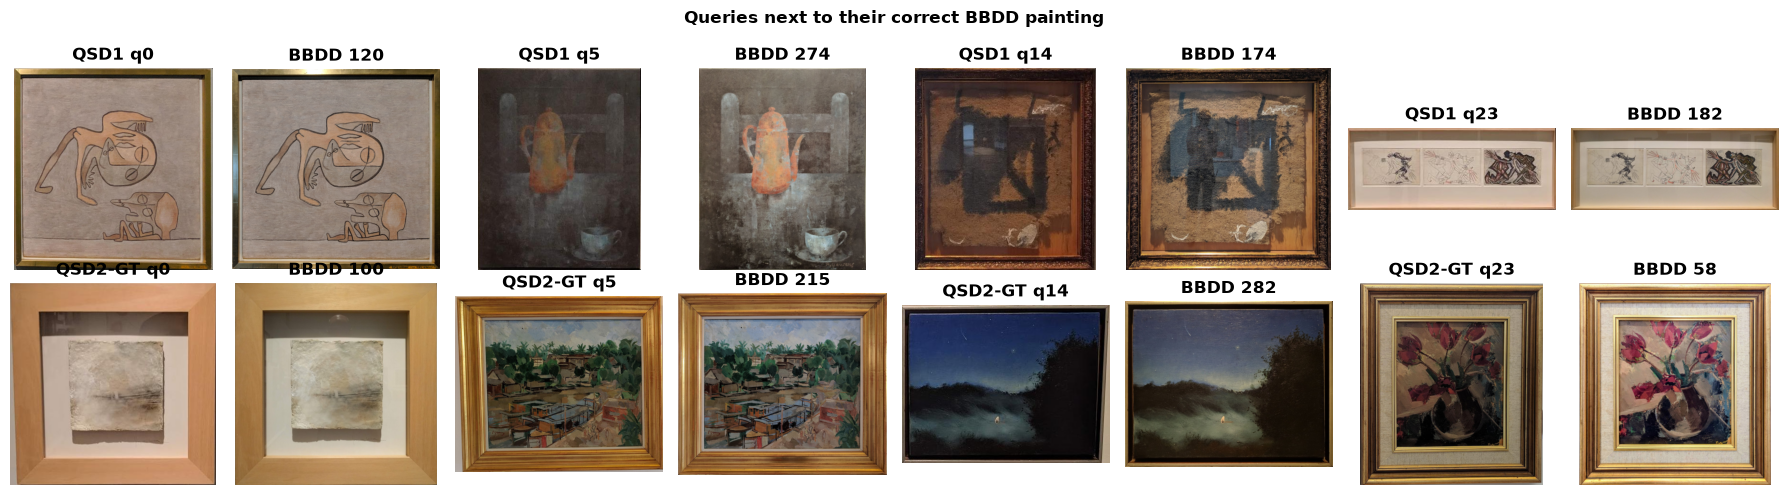

In [4]:
def bbox_crop(img, mask):
    x, y, w, h = cv2.boundingRect(mask.astype(np.uint8))
    return img[y:y + h, x:x + w]


QSD2_GTCROP = [resize_max(bbox_crop(im, m)) for im, m in zip(QSD2_FULL, QSD2_GTMASK)]

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for k, i in enumerate([0, 5, 14, 23]):
    for j, (img, title) in enumerate([(QSD1[i], f"QSD1 q{i}"), (BBDD[BBDD_IDS.index(GT1[i][0])], f"BBDD {GT1[i][0]}")]):
        axes[0, 2 * k + j].imshow(img[..., ::-1]); axes[0, 2 * k + j].set_title(title); axes[0, 2 * k + j].axis("off")
    for j, (img, title) in enumerate([(QSD2_GTCROP[i], f"QSD2-GT q{i}"), (BBDD[BBDD_IDS.index(GT2[i][0])], f"BBDD {GT2[i][0]}")]):
        axes[1, 2 * k + j].imshow(img[..., ::-1]); axes[1, 2 * k + j].set_title(title); axes[1, 2 * k + j].axis("off")
plt.suptitle("Queries next to their correct BBDD painting", fontweight="bold"); plt.tight_layout(); plt.show()

## 2. Task 1 – The descriptors

### 2.1 Pre-processing: illumination normalisation (from week 1)
The key finding of week 1: the queries differ from the BBDD mainly in **illumination** (exposure and colour of the light).
A light change multiplies each RGB channel by a constant (diagonal / von Kries model), so dividing each channel by its mean
cancels it. We scale each channel so that its mean is 128. This took week 1 from 0.59 to 0.95 mAP@5.

In [5]:
def channel_mean_128(img, target=128):
    """Illumination normalisation: scale each B, G, R channel so that its mean is `target`."""
    f = img.astype(np.float32)
    means = f.reshape(-1, 3).mean(axis=0)
    return np.clip(f * (target / (means + EPS)), 0, 255).astype(np.uint8)


def inner_crop(img, margin):
    """Remove a `margin` fraction of the image on each side (used in §6 to be robust to imperfect masks)."""
    if margin <= 0:
        return img
    h, w = img.shape[:2]
    dy, dx = int(margin * h), int(margin * w)
    return img[dy:h - dy, dx:w - dx]

### 2.2 Colour spaces and where the bins are placed

A histogram counts how many pixels fall in each **bin** (a range of values). For a joint (2D/3D) histogram each bin is a
box in the colour space. Before choosing *how many* bins, we must look at *where* the values actually are.

**Why:** the feedback slide of last year says *"All teams used a uniform # of bins across channels, even if in some cases
the ranges are not the same"*. In OpenCV's 8-bit conversions, the chroma channels of **Lab (a, b)** and **YCrCb (Cr, Cb)**
only use a narrow part of [0, 255]: a uniform split of [0, 255] wastes most bins.

We implement three ways of placing the bin edges:
- `uniform`: equal-width bins over the full range of the channel (what everybody does);
- `range`: equal-width bins over the range that the data really uses (0.5–99.5 percentile of the BBDD pixels);
- `quantile`: equal-probability bins (each bin receives the same number of BBDD pixels: adaptive binning).

The number of bins can also be different per channel, e.g. `(8, 16, 16)` = 8 bins for the luminance, 16 for each chroma channel.

In [6]:
# name -> (OpenCV conversion from BGR, value range of each channel, channel names)
SPACES = {
    "RGB": (None, [(0, 256)] * 3, ["B", "G", "R"]),
    "HSV": (cv2.COLOR_BGR2HSV, [(0, 180), (0, 256), (0, 256)], ["H", "S", "V"]),   # OpenCV hue is in [0, 180)
    "LAB": (cv2.COLOR_BGR2LAB, [(0, 256)] * 3, ["L", "a", "b"]),
    "YCRCB": (cv2.COLOR_BGR2YCrCb, [(0, 256)] * 3, ["Y", "Cr", "Cb"]),
}
LUMA = {"HSV": 2, "LAB": 0, "YCRCB": 0, "RGB": None}           # brightness channel
CHROMA = {"HSV": (0, 1), "LAB": (1, 2), "YCRCB": (1, 2), "RGB": (2, 1)}


def convert(img, space):
    code = SPACES[space][0]
    return img if code is None else cv2.cvtColor(img, code)


def as3(bins):
    return (bins,) * 3 if np.isscalar(bins) else tuple(bins)


def make_edges(space, bins, scheme="uniform", pixels=None):
    """Bin edges per channel. `pixels`: (N, 3) sample of BBDD pixels in `space` (needed for 'range' and 'quantile')."""
    edges = []
    for c, n in enumerate(as3(bins)):
        lo, hi = SPACES[space][1][c]
        if scheme == "uniform":
            e = np.linspace(lo, hi, n + 1)
        elif scheme == "range":
            a, b = np.percentile(pixels[:, c], [0.5, 99.5])
            e = np.linspace(a, b, n + 1); e[0], e[-1] = -1, 256           # outliers go to the first / last bin
        elif scheme == "quantile":
            e = np.quantile(pixels[:, c], np.linspace(0, 1, n + 1)); e[0], e[-1] = -1, 256
            if len(np.unique(e)) < n + 1:                                  # degenerate channel -> uniform
                e = np.linspace(-1, 256, n + 1)
        else:
            raise ValueError(scheme)
        edges.append(e)
    return edges


_PIXEL_CACHE = {}


def bbdd_pixels(space, n=300_000, margin=0.0):
    """Random sample of BBDD pixels (after illumination normalisation) in `space`; used to place 'range'/'quantile' bins."""
    key = (space, margin)
    if key not in _PIXEL_CACHE:
        P = np.concatenate([convert(channel_mean_128(inner_crop(x, margin)), space).reshape(-1, 3) for x in BBDD])
        _PIXEL_CACHE[key] = P[np.random.default_rng(0).choice(len(P), n, replace=False)].astype(np.float64)
    return _PIXEL_CACHE[key]

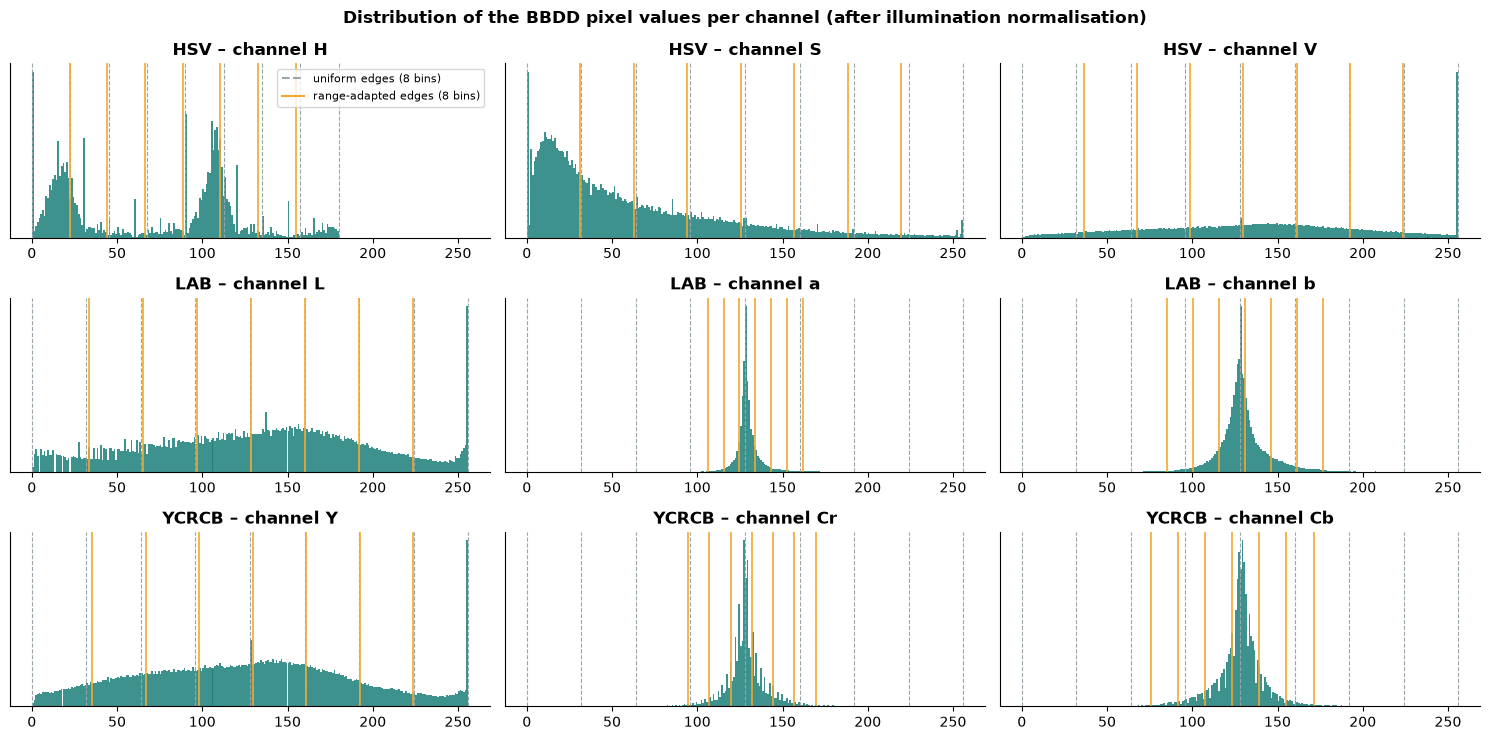

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 7.5))
for r, space in enumerate(["HSV", "LAB", "YCRCB"]):
    P = bbdd_pixels(space)
    for c in range(3):
        ax = axes[r, c]
        ax.hist(P[:, c], bins=256, range=(0, 256), color=TEAL, alpha=0.85)
        for e in make_edges(space, 8, "uniform")[c]:
            ax.axvline(e, color=GREY, lw=0.8, ls="--")
        for e in make_edges(space, 8, "range", P)[c][1:-1]:
            ax.axvline(e, color=ORANGE, lw=1.2)
        ax.set_title(f"{space} – channel {SPACES[space][2][c]}"); ax.set_yticks([])
axes[0, 0].plot([], [], color=GREY, ls="--", label="uniform edges (8 bins)"); axes[0, 0].plot([], [], color=ORANGE, label="range-adapted edges (8 bins)")
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.suptitle("Distribution of the BBDD pixel values per channel (after illumination normalisation)", fontweight="bold")
plt.tight_layout(); savefig("bin_ranges"); plt.show()

**What we see:** in Lab the channels a and b live roughly in [100, 170] and in YCrCb the channels Cr and Cb in
[105, 160]. With 8 uniform bins over [0, 255] (grey dashed lines), **almost all the pixels fall in only 2–3 bins**: the
histogram can barely distinguish colours. Adapting the edges to the real range (orange) uses all of them. HSV and RGB
already use their whole range, so for them it should not matter. We test this in §3.3.

### 2.3 Histograms of a region: 1D, 2D and 3D

- **1D (week 1):** one histogram per channel, concatenated. It loses the relation between channels: "many dark pixels" and
  "many red pixels" look the same whether the red pixels are dark or bright.
- **2D:** joint histogram of the two **chroma** channels (H–S, a–b, Cr–Cb). Ignores the brightness.
- **2D + 1D:** the 2D chroma histogram plus a 1D histogram of the brightness channel.
- **3D:** joint histogram of the three channels: each bin is a small box of colours. It keeps all the information about
  which colours appear, at the price of many bins (8×8×8 = 512, 16×16×16 = 4096).

**Implementation.** We first map every pixel to its bin index once (`quantize`, with a 256-entry lookup table per channel
because the values are 8-bit). Then the histogram of any region is a `np.bincount` over that region, which makes block
histograms cheap. Every component is normalised to sum 1, so the image size does not matter. We checked that for uniform
bins this gives exactly the same result as `cv2.calcHist`.

In [8]:
def quantize(x, edges):
    """x: HxWx3 uint8 image (already in the colour space) -> HxWx3 array with the bin index of every pixel and channel."""
    luts = [np.clip(np.searchsorted(e[1:-1], np.arange(256), side="right"), 0, len(e) - 2) for e in edges]
    return np.stack([luts[c][x[..., c]] for c in range(3)], axis=-1)


def index_maps(q, kind, nbins, space):
    """Turn the per-channel bin indices into one index per histogram component -> list of (index map, number of bins)."""
    nb = nbins
    if kind == "3d":
        return [(q[..., 0] * nb[1] * nb[2] + q[..., 1] * nb[2] + q[..., 2], nb[0] * nb[1] * nb[2])]
    if kind == "1d":
        return [(q[..., c], nb[c]) for c in range(3)]
    c0, c1 = CHROMA[space]
    comps = [(q[..., c0] * nb[c1] + q[..., c1], nb[c0] * nb[c1])]                # 2D chroma histogram
    if kind == "2d+1d":
        comps.append((q[..., LUMA[space]], nb[LUMA[space]]))                     # + 1D brightness histogram
    return comps


def region_hist(comps, ys=slice(None), xs=slice(None)):
    """Normalised histogram of a rectangular region (every component sums to 1, the whole vector sums to 1)."""
    out = []
    for idx, n in comps:
        h = np.bincount(idx[ys, xs].ravel(), minlength=n).astype(np.float32)
        out.append(h / (h.sum() + EPS))
    return np.concatenate(out) / len(out)

### 2.4 Block histograms and the spatial pyramid

A global histogram does not know **where** each colour is: two paintings with the same palette are indistinguishable
(this was the main remaining error of week 1).
- **Block histogram:** divide the image into an n×n grid of non-overlapping blocks, compute the histogram of each block
  and concatenate them. Dimension = n² × bins.
- **Spatial pyramid** (Lazebnik et al., 2006): concatenate the block histograms of several levels, e.g. 1×1 + 2×2 + 4×4,
  each multiplied by a weight. Coarse levels are robust to small misalignments; fine levels are more discriminative. The
  classical choice gives **more weight to the finer levels**.

Each level is normalised so that it sums to its weight, so all levels are comparable.

In [9]:
def grid_cells(h, w, n):
    ys, xs = np.linspace(0, h, n + 1).astype(int), np.linspace(0, w, n + 1).astype(int)
    return [(ys[i], ys[i + 1], xs[j], xs[j + 1]) for i in range(n) for j in range(n)]


def spatial_hist(comps, shape, levels=(1,), weights=None):
    """Block histogram (one level) or spatial pyramid (several levels). levels = grid sizes, e.g. (1, 2, 4)."""
    h, w = shape
    weights = np.array(weights if weights is not None else [1.0] * len(levels), float)
    weights = weights / weights.sum()
    parts = []
    for n, wl in zip(levels, weights):
        cells = grid_cells(h, w, n)
        blocks = [region_hist(comps, slice(y0, y1), slice(x0, x1)) for y0, y1, x0, x1 in cells]
        parts.append(wl * np.concatenate(blocks) / len(cells))
    return np.concatenate(parts)


def describe(img, space="HSV", kind="3d", edges=None, levels=(1,), weights=None, margin=0.0):
    """Full descriptor of one image: (inner crop) -> illumination normalisation -> colour space -> quantize -> blocks."""
    x = convert(channel_mean_128(inner_crop(img, margin)), space)
    nb = [len(e) - 1 for e in edges]
    return spatial_hist(index_maps(quantize(x, edges), kind, nb, space), x.shape[:2], levels, weights)


# sanity check against OpenCV's calcHist (uniform bins, 3D, whole image)
_x = convert(channel_mean_128(BBDD[3]), "LAB")
_ref = cv2.calcHist([_x], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3).ravel()
_ours = describe(BBDD[3], "LAB", "3d", make_edges("LAB", 8))
print("max |ours - cv2.calcHist| =", np.abs(_ours - _ref / _ref.sum()).max())

max |ours - cv2.calcHist| = 0.0


### 2.5 Visualising the histograms

To check that the histograms make sense, we draw them as in the task slides. Each bar of a 3D histogram is painted with
the **colour of the centre of its bin**, so a 3D histogram reads like a palette of the painting. We compare a query with
its correct BBDD painting (they should look alike) and with a different painting.

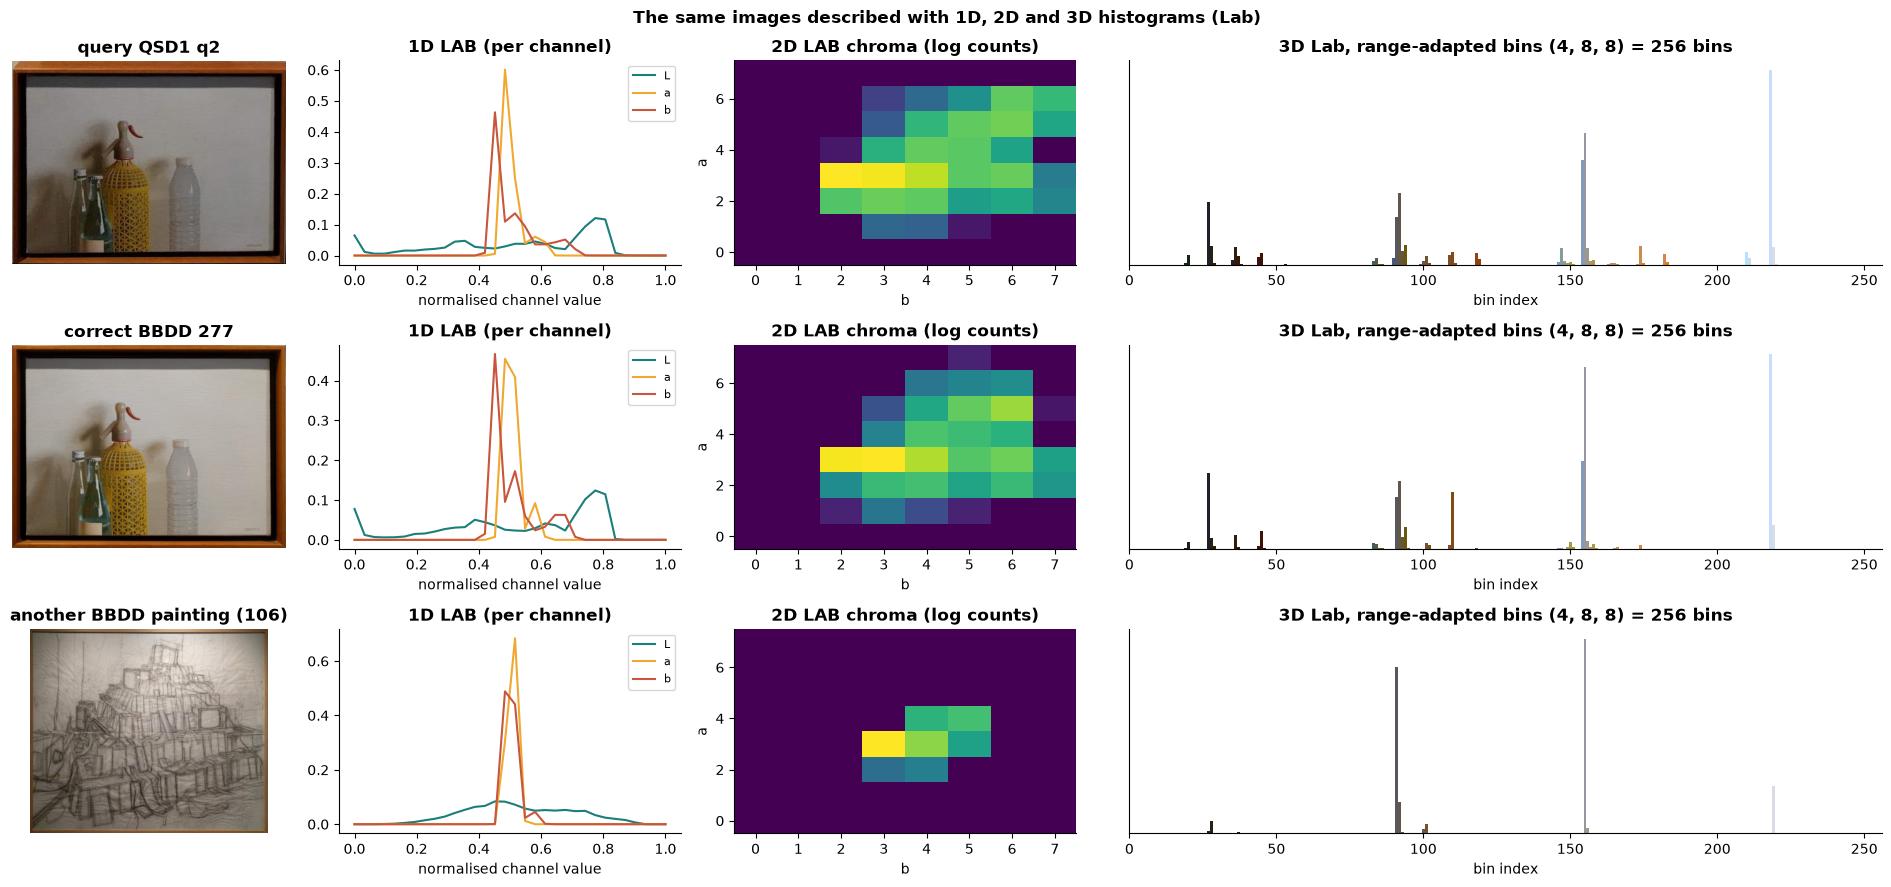

In [10]:
INV = {"HSV": cv2.COLOR_HSV2RGB, "LAB": cv2.COLOR_LAB2RGB, "YCRCB": cv2.COLOR_YCrCb2RGB}


def bin_colours(space, edges):
    """RGB colour (0-1) of the centre of every 3D bin, in the same order as the 3D histogram."""
    centres = [np.clip((e[:-1] + e[1:]) / 2, 0, 255) for e in edges]
    g = np.stack(np.meshgrid(*centres, indexing="ij"), -1).reshape(-1, 1, 3).astype(np.uint8)
    rgb = cv2.cvtColor(g, INV[space]) if space in INV else g[..., ::-1]
    return rgb.reshape(-1, 3) / 255


def plot_1d(ax, img, space, bins=32):
    x = convert(channel_mean_128(img), space)
    cols = [TEAL, ORANGE, RED]
    for c in range(3):
        lo, hi = SPACES[space][1][c]
        h = cv2.calcHist([x], [c], None, [bins], [lo, hi]).ravel(); h /= h.sum()
        ax.plot(np.linspace(0, 1, bins), h, color=cols[c], label=SPACES[space][2][c])
    ax.set_xlabel("normalised channel value"); ax.legend(fontsize=8); ax.set_title(f"1D {space} (per channel)")


def plot_2d(ax, img, space, edges):
    x = convert(channel_mean_128(img), space)
    c0, c1 = CHROMA[space]
    q = quantize(x, edges)
    n0, n1 = len(edges[c0]) - 1, len(edges[c1]) - 1
    h = np.bincount((q[..., c0] * n1 + q[..., c1]).ravel(), minlength=n0 * n1).reshape(n0, n1)
    ax.imshow(np.log1p(h), cmap="viridis", origin="lower", aspect="auto")
    ax.set_xlabel(SPACES[space][2][c1]); ax.set_ylabel(SPACES[space][2][c0]); ax.set_title(f"2D {space} chroma (log counts)")


def plot_3d(ax, img, space, edges, title=None):
    h = describe(img, space, "3d", edges)
    ax.bar(np.arange(len(h)), h, width=1.0, color=bin_colours(space, edges), edgecolor="none")
    ax.set_xlim(0, len(h)); ax.set_title(title or f"3D {space} {tuple(len(e) - 1 for e in edges)} = {len(h)} bins")
    ax.set_xlabel("bin index"); ax.set_yticks([])


q = 2                                      # a query with a clear palette
img_q, img_ok = QSD1[q], BBDD[BBDD_IDS.index(GT1[q][0])]
img_other = BBDD[BBDD_IDS.index(106)]
E_lab_u = make_edges("LAB", (4, 8, 8), "uniform")
E_lab_r = make_edges("LAB", (4, 8, 8), "range", bbdd_pixels("LAB"))

fig, axes = plt.subplots(3, 4, figsize=(19, 9), gridspec_kw=dict(width_ratios=[0.8, 1, 1, 2.2]))
for r, (img, name) in enumerate([(img_q, f"query QSD1 q{q}"), (img_ok, f"correct BBDD {GT1[q][0]}"), (img_other, "another BBDD painting (106)")]):
    axes[r, 0].imshow(img[..., ::-1]); axes[r, 0].set_title(name); axes[r, 0].axis("off")
    plot_1d(axes[r, 1], img, "LAB")
    plot_2d(axes[r, 2], img, "LAB", E_lab_r)
    plot_3d(axes[r, 3], img, "LAB", E_lab_r, f"3D Lab, range-adapted bins (4, 8, 8) = 256 bins")
plt.suptitle("The same images described with 1D, 2D and 3D histograms (Lab)", fontweight="bold"); plt.tight_layout(); savefig("hist_1d_2d_3d"); plt.show()

The query and its correct painting have almost the same 3D histogram (same bars, same colours, similar heights), while the
other painting has a completely different palette. The 2D chroma histogram also matches, but it ignores how bright each
colour is.

**Uniform vs range-adapted bins in Lab.** Same 3D histogram (4, 8, 8) of the query, with the two ways of placing the edges:

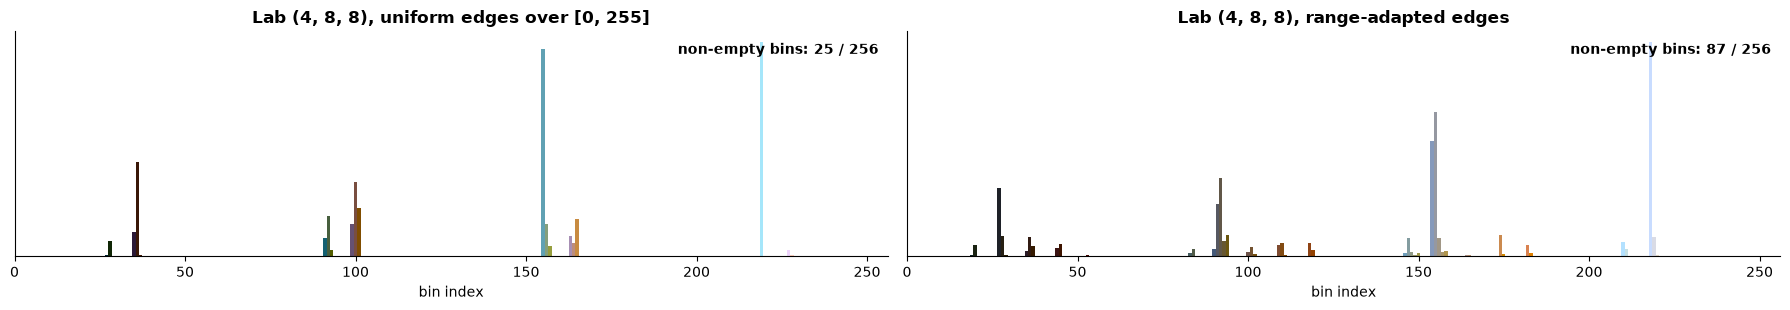

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 3.2))
plot_3d(axes[0], img_q, "LAB", E_lab_u, "Lab (4, 8, 8), uniform edges over [0, 255]")
plot_3d(axes[1], img_q, "LAB", E_lab_r, "Lab (4, 8, 8), range-adapted edges")
for ax, E in zip(axes, [E_lab_u, E_lab_r]):
    used = (describe(img_q, "LAB", "3d", E) > 0).sum()
    ax.text(0.99, 0.9, f"non-empty bins: {used} / 256", transform=ax.transAxes, ha="right", fontweight="bold")
plt.tight_layout(); savefig("lab_uniform_vs_range"); plt.show()

With uniform edges only a handful of the 256 bins are used (all the colours of the painting collapse into a few bins);
with range-adapted edges the same 256 bins describe the palette in much more detail.

### 2.6 Visualising block histograms and the spatial pyramid
As in the slides of the task: the image divided into blocks, and the histogram of each block. We use a compact 3D HSV
histogram (4×4×4 = 64 bins) so that each small plot is readable.

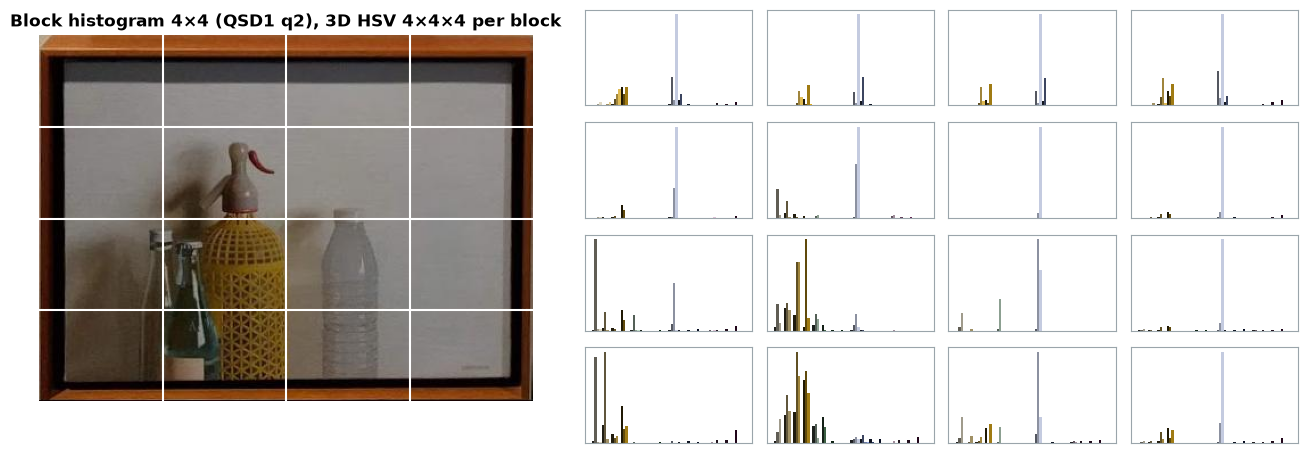

In [12]:
def draw_grid(ax, img, n, color="white"):
    h, w = img.shape[:2]
    ax.imshow(img[..., ::-1])
    for k in range(1, n):
        ax.axhline(k * h / n, color=color, lw=1.5); ax.axvline(k * w / n, color=color, lw=1.5)
    ax.axis("off")


def block_hist_figure(img, n, space="HSV", edges=None, title=""):
    edges = edges or make_edges(space, 4)
    x = convert(channel_mean_128(img), space)
    comps = index_maps(quantize(x, edges), "3d", [len(e) - 1 for e in edges], space)
    cols = bin_colours(space, edges)
    fig = plt.figure(figsize=(13, 5))
    ax0 = fig.add_axes([0.0, 0.05, 0.38, 0.9]); draw_grid(ax0, img, n); ax0.set_title(title)
    cells = grid_cells(*x.shape[:2], n)
    for k, (y0, y1, x0, x1) in enumerate(cells):
        i, j = divmod(k, n)
        ax = fig.add_axes([0.42 + j * 0.56 / n, 0.95 - (i + 1) * 0.9 / n, 0.56 / n * 0.92, 0.9 / n * 0.85])
        h = region_hist(comps, slice(y0, y1), slice(x0, x1))
        ax.bar(np.arange(len(h)), h, width=1, color=cols); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(True); s.set_color(GREY)
    return fig


block_hist_figure(QSD1[q], 4, title=f"Block histogram 4×4 (QSD1 q{q}), 3D HSV 4×4×4 per block"); savefig("block_hist"); plt.show()

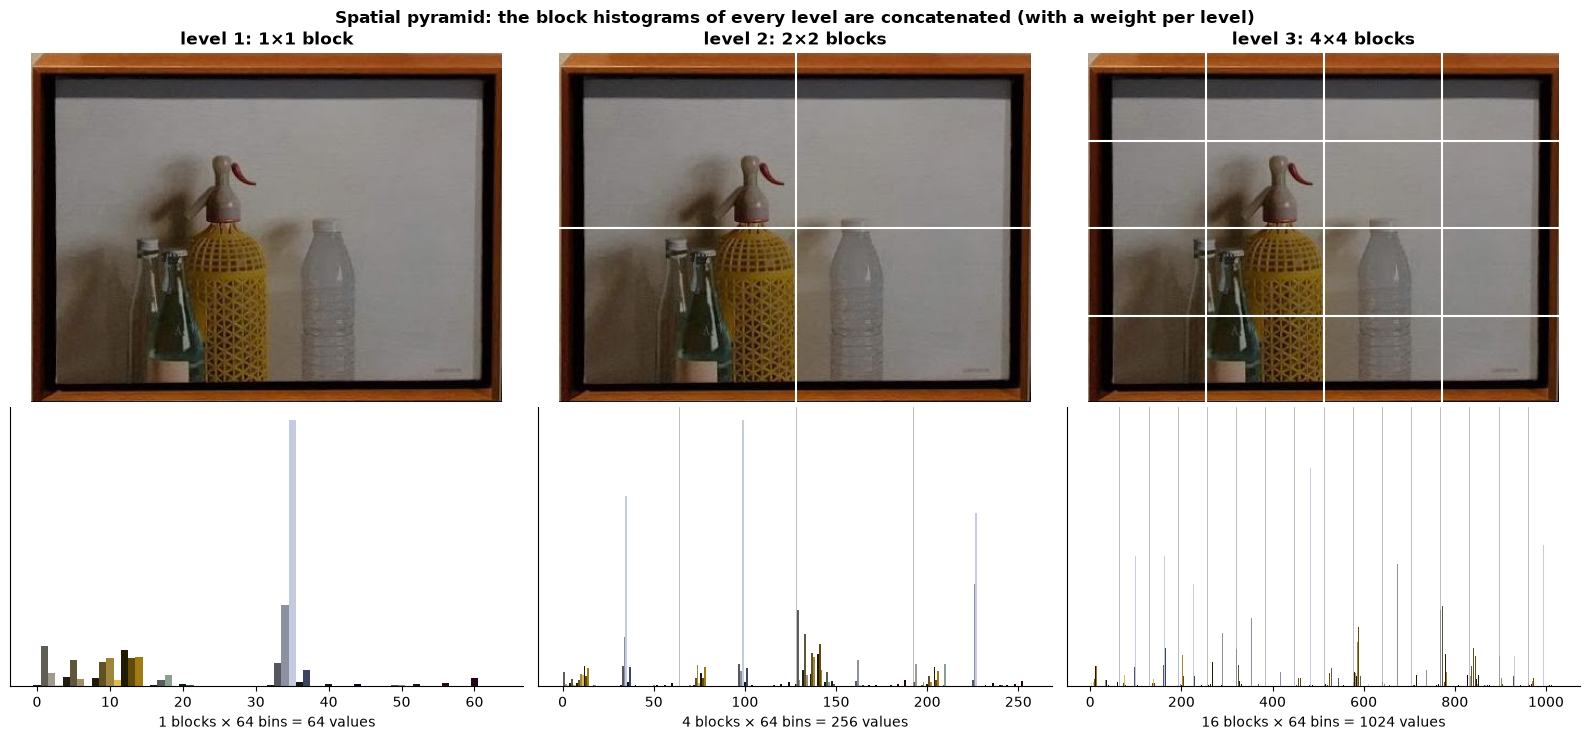

In [13]:
levels = [1, 2, 4]
edges_vis = make_edges("HSV", 4)
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), gridspec_kw=dict(height_ratios=[1, 0.8]))
x = convert(channel_mean_128(img_q), "HSV")
comps = index_maps(quantize(x, edges_vis), "3d", [4, 4, 4], "HSV")
for c, n in enumerate(levels):
    draw_grid(axes[0, c], img_q, n); axes[0, c].set_title(f"level {c + 1}: {n}×{n} block{'s' if n > 1 else ''}")
    h = spatial_hist(comps, x.shape[:2], (n,))
    axes[1, c].bar(np.arange(len(h)), h, width=1, color=np.tile(bin_colours("HSV", edges_vis), (n * n, 1)))
    for k in range(1, n * n):
        axes[1, c].axvline(k * 64, color=GREY, lw=0.5)
    axes[1, c].set_yticks([]); axes[1, c].set_xlabel(f"{n * n} blocks × 64 bins = {len(h)} values")
plt.suptitle("Spatial pyramid: the block histograms of every level are concatenated (with a weight per level)", fontweight="bold")
plt.tight_layout(); savefig("pyramid"); plt.show()

### 2.7 Distances
Same measures as in week 1. All of them return a distance (lower = more similar); the similarities are negated.
Week 1 showed that χ², Hellinger and Jensen–Shannon are the best and that Euclidean and correlation are the worst. With
normalised histograms, the intersection ranks exactly like L1, so we only keep L1.

In [14]:
def d_l1(q, D):        return np.abs(D - q).sum(1)
def d_euclidean(q, D): return np.sqrt(((D - q) ** 2).sum(1))
def d_chi2(q, D):      return ((D - q) ** 2 / (D + q + EPS)).sum(1)
def d_hellinger(q, D): return -np.sqrt(D * q).sum(1)                       # Hellinger kernel (similarity, negated)
def d_js(q, D):
    m = (D + q) / 2
    return (D * np.log((D + EPS) / (m + EPS)) + q * np.log((q + EPS) / (m + EPS))).sum(1)


DISTANCES = {"L1": d_l1, "euclidean": d_euclidean, "chi2": d_chi2, "hellinger": d_hellinger, "JS": d_js}

### 2.8 Retrieval and evaluation
For each query we rank the 287 BBDD paintings by distance. Metrics (same as week 1):
- **mAP@1**: fraction of queries whose first result is correct (the official, most demanding one);
- **mAP@5**: also gives partial credit (1/position) if the correct painting is in positions 2–5;
- **MRR** (mean reciprocal rank over the full ranking): like mAP but never 0, so it still separates two methods when both
  miss the same query. We use it to break ties, because many configurations reach the same mAP@1;
- **position** of the correct painting for each query.

In [15]:
def rank(Q, D, dist):
    return np.stack([np.argsort(DISTANCES[dist](q, D), kind="stable") for q in Q])


def apk(actual, predicted, k=10):
    """Average precision at k (benhamner/Metrics, as provided by the course)."""
    predicted = predicted[:k]
    score, hits = 0.0, 0.0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1
            score += hits / (i + 1.0)
    return score / min(len(actual), k) if actual else 0.0


def mapk(actual, predicted, k=10):
    return float(np.mean([apk(a, p, k) for a, p in zip(actual, predicted)]))


def evaluate(Q, D, gt, dist):
    preds = [[int(BBDD_IDS[i]) for i in o] for o in rank(Q, D, dist)]
    pos = np.array([p.index(g[0]) + 1 for p, g in zip(preds, gt)])
    return dict(map1=mapk(gt, preds, 1), map5=mapk(gt, preds, 5), mrr=float(np.mean(1 / pos)), pos=pos, preds=preds)

## 3. Experiments (Tasks 1 and 2)

**Protocol.** Every configuration is evaluated on QSD1 and on QSD2-GT (60 queries in total). We report the metrics of each
set and their mean. Each query is worth 1/30 = 0.033 of mAP@1 in its set, so **differences of one query are noise**: we
only trust a change if it is consistent across sets, colour spaces and bins.

`run_config` computes the descriptors of the BBDD and of the query sets for one configuration and evaluates them with
several distances. The converted images are cached so that the experiments run faster.

In [16]:
SETS = {"QSD1": (QSD1, GT1), "QSD2-GT": (QSD2_GTCROP, GT2)}
_PREP_CACHE = {}


def prepared(set_name, imgs, space, margin):
    """Images of one set after inner crop + illumination normalisation + colour conversion (cached)."""
    key = (set_name, space, margin)
    if key not in _PREP_CACHE:
        _PREP_CACHE[key] = [convert(channel_mean_128(inner_crop(x, margin)), space) for x in imgs]
    return _PREP_CACHE[key]


def descriptors(set_name, imgs, space, kind, edges, levels, weights, margin):
    nb = [len(e) - 1 for e in edges]
    return np.stack([spatial_hist(index_maps(quantize(x, edges), kind, nb, space), x.shape[:2], levels, weights)
                     for x in prepared(set_name, imgs, space, margin)])


def run_config(space, kind="3d", bins=8, scheme="uniform", levels=(1,), weights=None, margin=0.0,
               dists=("chi2", "hellinger"), sets=("QSD1", "QSD2-GT"), keep_pos=False):
    edges = make_edges(space, bins, scheme, bbdd_pixels(space, margin=margin) if scheme != "uniform" else None)
    D = descriptors("BBDD", BBDD, space, kind, edges, levels, weights, margin)
    Q = {s: descriptors(s, SETS[s][0], space, kind, edges, levels, weights, margin) for s in sets}
    rows = []
    for d in dists:
        row = dict(space=space, kind=kind, bins=str(as3(bins)), scheme=scheme, levels=str(tuple(levels)),
                   weights="uniform" if weights is None else str(tuple(weights)), margin=margin, dist=d, dim=D.shape[1])
        for s in sets:
            r = evaluate(Q[s], D, SETS[s][1], d)
            row.update({f"{s} mAP@1": r["map1"], f"{s} mAP@5": r["map5"], f"{s} MRR": r["mrr"]})
            if keep_pos:
                row[f"{s} pos"] = r["pos"]
        for m in ("mAP@1", "mAP@5", "MRR"):
            row[m] = np.mean([row[f"{s} {m}"] for s in sets])
        rows.append(row)
    return rows


def show(df, cols=None, sort="MRR", n=None):
    cols = cols or [c for c in df.columns if not c.endswith("pos")]
    out = df.sort_values([sort, "mAP@1"], ascending=False)[cols]
    return (out.head(n) if n else out).round(3)

### 3.1 Starting point: the two methods of week 1
**Why:** to know where we start, and to check how the week-1 descriptors (global 1D histograms) behave on the new
QSD2-GT set.

In [17]:
t0 = time.time()
w1 = pd.DataFrame(run_config("HSV", "1d", 16, dists=("chi2",)) + run_config("LAB", "1d", 32, dists=("hellinger",)))
w1.insert(0, "method", ["W1 method 1", "W1 method 2"])
display(show(w1, ["method", "space", "bins", "dist", "QSD1 mAP@1", "QSD1 mAP@5", "QSD2-GT mAP@1", "QSD2-GT mAP@5", "mAP@1", "MRR"]))
print(f"{time.time() - t0:.0f}s")

,method,space,bins,dist,QSD1 mAP@1,QSD1 mAP@5,QSD2-GT mAP@1,QSD2-GT mAP@5,mAP@1,MRR
1,W1 method 2,LAB,"(32, 32, 32)",hellinger,0.9,0.922,0.700,0.754,0.800,0.845
0,W1 method 1,HSV,"(16, 16, 16)",chi2,0.9,0.950,0.567,0.638,0.733,0.805


6s


**Result:** we reproduce the week-1 numbers on QSD1 (0.90 / 0.95 and 0.90 / 0.92), but on QSD2-GT the same descriptors
drop a lot, even though the crops are perfect. The week-1 methods were tuned to QSD1; this is consistent with the 0.77 we
got on the test set. **Validating on two sets is necessary.**

### 3.2 1D vs 2D vs 3D, colour space and number of bins (global histograms)
**Why:** this is the first part of Task 1. We compare the four histogram types in four colour spaces with a range of
bins, to see (a) which type is better and (b) the effect of the number of bins (curse of dimensionality: with too many
bins each bin gets few pixels, and a small change of light moves pixels to a neighbouring bin). All with uniform bins.

In [18]:
t0 = time.time()
grid = {"1d": [8, 16, 32, 64], "2d": [8, 16, 32], "2d+1d": [8, 16, 32], "3d": [4, 6, 8, 12, 16, 24]}
rows = []
for space in ["RGB", "HSV", "LAB", "YCRCB"]:
    for kind, bin_list in grid.items():
        if space == "RGB" and kind in ("2d", "2d+1d"):
            continue                                   # RGB has no separate chroma / brightness channels
        for b in bin_list:
            rows += run_config(space, kind, b)
exp_kind = pd.DataFrame(rows)
print(f"{len(exp_kind)} configurations in {time.time() - t0:.0f}s")
best_kind = exp_kind.groupby(["space", "kind"])[["mAP@1", "MRR"]].max().unstack("kind").round(3)
display(best_kind)

116 configurations in 71s


mAP@1                         MRR                     
kind      1d     2d  2d+1d     3d     1d     2d  2d+1d     3d
space                                                        
HSV    0.733  0.700  0.783  0.900  0.820  0.764  0.840  0.933
LAB    0.800  0.700  0.817  0.883  0.845  0.774  0.875  0.926
RGB    0.683    NaN    NaN  0.917  0.744    NaN    NaN  0.944
YCRCB  0.733  0.617  0.833  0.917  0.815  0.726  0.882  0.940

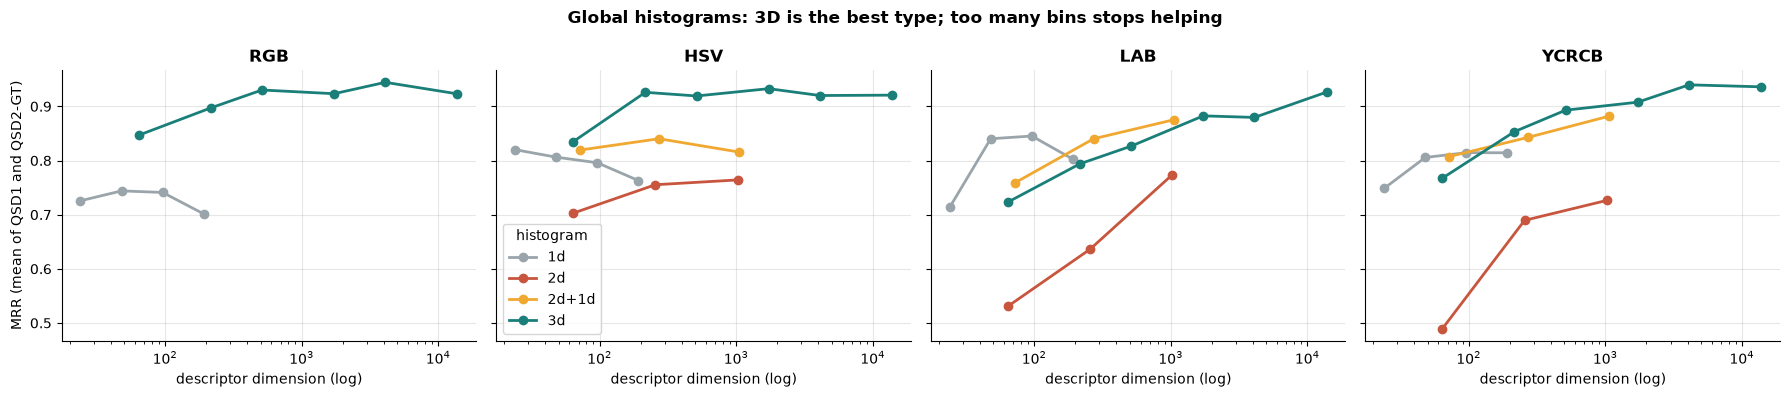

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
kind_colors = {"1d": GREY, "2d": RED, "2d+1d": ORANGE, "3d": TEAL}
for ax, space in zip(axes, ["RGB", "HSV", "LAB", "YCRCB"]):
    for kind, col in kind_colors.items():
        d = exp_kind[(exp_kind.space == space) & (exp_kind.kind == kind)].groupby("dim")["MRR"].max()
        if len(d):
            ax.plot(d.index, d.values, "o-", color=col, label=kind, lw=2)
    ax.set_xscale("log"); ax.set_title(space); ax.set_xlabel("descriptor dimension (log)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("MRR (mean of QSD1 and QSD2-GT)"); axes[1].legend(title="histogram")
plt.suptitle("Global histograms: 3D is the best type; too many bins stops helping", fontweight="bold")
plt.tight_layout(); savefig("kinds_bins"); plt.show()

**Result and conclusions**
- **3D is clearly the best type in every colour space.** The 1D histograms of week 1 lose the relation between channels.
- **2D (chroma only) is the worst**: once the illumination is normalised, the brightness is informative (the same
  conclusion as week 1). Adding it back as a 1D histogram (2D+1D) helps, but a joint 3D histogram is better.
- **Curse of dimensionality:** for 3D in RGB, HSV and YCrCb the curve rises up to about 8–16 bins per channel (512–4096
  bins) and then flattens or drops: more bins only help while each bin still receives enough pixels.
- **Lab keeps improving with more bins** instead: with uniform edges most Lab bins are empty (§2.2), so it needs many bins
  to reach the same resolution in a and b. This is fixed in §3.3.

### 3.3 Where to place the bins: uniform vs range-adapted vs quantile, and different bins per channel
**Why:** §2.2 showed that a and b (Lab) and Cr and Cb (YCrCb) only use a narrow part of [0, 255]. We test the three ways of
placing the edges, with the same number of bins for every channel and with fewer bins for the brightness than for the chroma.

In [20]:
t0 = time.time()
bin_options = {"RGB": [8, 12], "HSV": [8, (16, 8, 8)], "LAB": [8, (8, 16, 16)], "YCRCB": [8, (8, 16, 16)]}
rows = []
for space, blist in bin_options.items():
    for b in blist:
        for scheme in ["uniform", "range", "quantile"]:
            rows += run_config(space, "3d", b, scheme)
exp_scheme = pd.DataFrame(rows)
print(f"{time.time() - t0:.0f}s")
display(exp_scheme.pivot_table(index=["space", "bins"], columns="scheme", values="MRR", aggfunc="max").round(3))

25s


scheme              quantile  range  uniform
space bins                                  
HSV   (16, 8, 8)       0.918  0.920    0.919
      (8, 8, 8)        0.919  0.918    0.919
LAB   (8, 16, 16)      0.897  0.917    0.874
      (8, 8, 8)        0.915  0.915    0.827
RGB   (12, 12, 12)     0.935  0.924    0.923
      (8, 8, 8)        0.928  0.923    0.930
YCRCB (8, 16, 16)      0.931  0.956    0.939
      (8, 8, 8)        0.919  0.915    0.893

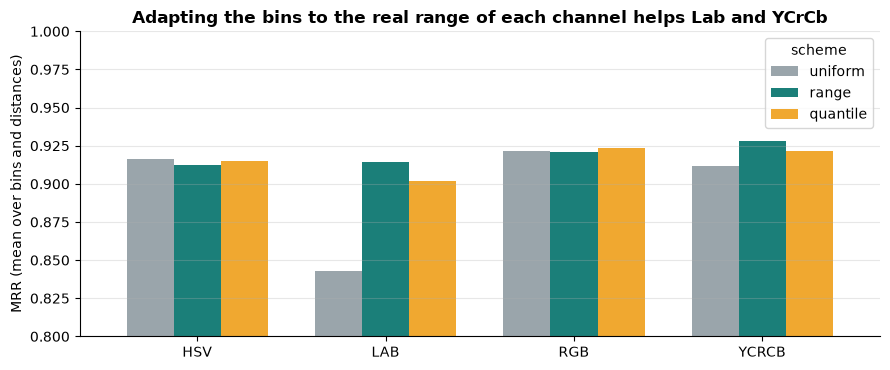

In [21]:
piv = exp_scheme.groupby(["space", "scheme"])["MRR"].mean().unstack()[["uniform", "range", "quantile"]]
ax = piv.plot.bar(color=[GREY, TEAL, ORANGE], figsize=(9, 3.8), rot=0, width=0.75)
ax.set_ylim(0.8, 1.0); ax.set_ylabel("MRR (mean over bins and distances)"); ax.set_xlabel("")
ax.set_title("Adapting the bins to the real range of each channel helps Lab and YCrCb"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); savefig("bin_scheme"); plt.show()

**Result and conclusions**
- **Lab and YCrCb improve clearly with range-adapted (or quantile) bins**, exactly as predicted in §2.2: with uniform
  edges most chroma bins are empty.
- **HSV and RGB do not change** (their channels already use the full range), which confirms the explanation.
- Range-adapted and quantile bins are similar; we keep **`range`** (equal width over the real range), which is simpler.
- Using **fewer bins for the brightness than for the chroma**, e.g. (8, 16, 16), is a good choice for Lab and YCrCb:
  this answers the remark of last year's feedback ("uniform # of bins across channels even if the ranges are not the
  same").

From now on Lab and YCrCb use `range` bins and HSV and RGB use `uniform` bins.

In [22]:
SCHEME = {"RGB": "uniform", "HSV": "uniform", "LAB": "range", "YCRCB": "range"}

### 3.4 Block histograms: number of blocks vs number of bins
**Why:** this is the core of Task 1. Blocks add *where* each colour is. But the dimension is blocks × bins, and each block
has fewer pixels than the whole image, so with many blocks we probably need fewer bins (curse of dimensionality again).
We explore both at the same time and show the result as a heat map.

In [23]:
t0 = time.time()
block_bins = {"HSV": [(4, 4, 4), (8, 6, 6), (12, 8, 8)], "LAB": [(4, 8, 8), (8, 16, 16)], "YCRCB": [(4, 8, 8), (6, 12, 12)]}
GRIDS = [1, 2, 3, 4, 5, 6, 8]
rows = []
for space, blist in block_bins.items():
    for b in blist:
        for n in GRIDS:
            rows += [dict(r, grid=n) for r in run_config(space, "3d", b, SCHEME[space], levels=(n,), dists=("hellinger", "chi2"))]
exp_blocks = pd.DataFrame(rows)
print(f"{len(exp_blocks)} configurations in {time.time() - t0:.0f}s")
display(show(exp_blocks, ["space", "bins", "grid", "dist", "dim", "QSD1 mAP@1", "QSD2-GT mAP@1", "mAP@1", "mAP@5", "MRR"], n=12))

98 configurations in 103s


,space,bins,grid,dist,dim,QSD1 mAP@1,QSD2-GT mAP@1,mAP@1,mAP@5,MRR
9,HSV,"(4, 4, 4)",5,chi2,1600,0.967,1.0,0.983,0.988,0.988
8,HSV,"(4, 4, 4)",5,hellinger,1600,0.967,1.0,0.983,0.987,0.987
35,HSV,"(12, 8, 8)",4,chi2,12288,0.967,1.0,0.983,0.987,0.987
10,HSV,"(4, 4, 4)",6,hellinger,2304,0.967,1.0,0.983,0.983,0.986
11,HSV,"(4, 4, 4)",6,chi2,2304,0.967,1.0,0.983,0.983,0.986
23,HSV,"(8, 6, 6)",5,chi2,7200,0.967,1.0,0.983,0.983,0.986
25,HSV,"(8, 6, 6)",6,chi2,10368,0.967,1.0,0.983,0.983,0.986
34,HSV,"(12, 8, 8)",4,hellinger,12288,0.967,1.0,0.983,0.983,0.986
13,HSV,"(4, 4, 4)",8,chi2,4096,0.967,1.0,0.983,0.983,0.985
27,HSV,"(8, 6, 6)",8,chi2,18432,0.967,1.0,0.983,0.983,0.985


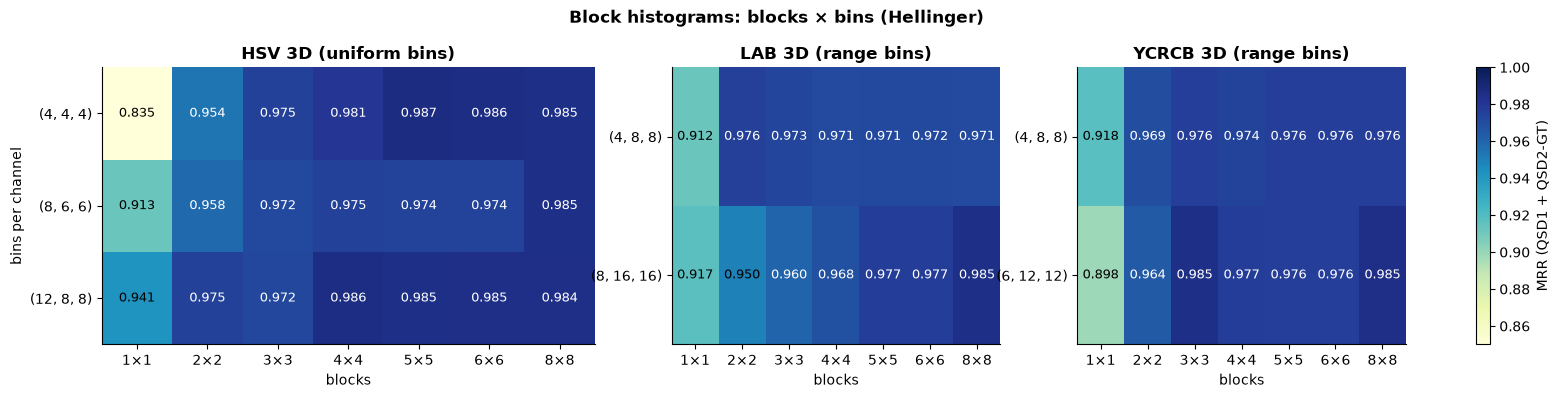

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6), gridspec_kw=dict(width_ratios=[3, 2, 2]))
for ax, space in zip(axes, block_bins):
    d = exp_blocks[(exp_blocks.space == space) & (exp_blocks.dist == "hellinger")]
    piv = d.pivot_table(index="bins", columns="grid", values="MRR").reindex([str(as3(b)) for b in block_bins[space]])
    im = ax.imshow(piv.values, cmap="YlGnBu", vmin=0.85, vmax=1.0, aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if piv.values[i, j] > 0.95 else "black")
    ax.set_xticks(range(len(GRIDS)), [f"{n}×{n}" for n in GRIDS]); ax.set_yticks(range(len(piv)), piv.index)
    ax.set_xlabel("blocks"); ax.set_title(f"{space} 3D ({SCHEME[space]} bins)")
axes[0].set_ylabel("bins per channel")
plt.colorbar(im, ax=axes, fraction=0.015, label="MRR (QSD1 + QSD2-GT)")
plt.suptitle("Block histograms: blocks × bins (Hellinger)", fontweight="bold", y=1.04); savefig("blocks_heatmap"); plt.show()

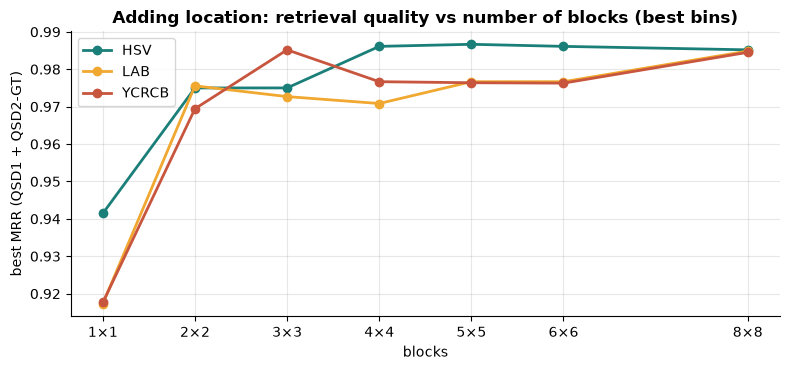

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for space, col in zip(block_bins, [TEAL, ORANGE, RED]):
    d = exp_blocks[(exp_blocks.space == space) & (exp_blocks.dist == "hellinger")].groupby("grid")[["mAP@1", "MRR"]].max()
    ax.plot(d.index, d["MRR"], "o-", color=col, lw=2, label=f"{space}")
ax.set_xticks(GRIDS, [f"{n}×{n}" for n in GRIDS]); ax.set_ylabel("best MRR (QSD1 + QSD2-GT)"); ax.set_xlabel("blocks")
ax.set_title("Adding location: retrieval quality vs number of blocks (best bins)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); savefig("blocks_curve"); plt.show()

**Result and conclusions**
- **Blocks are the biggest improvement of the week.** Going from 1×1 to 3×3 or 4×4 blocks raises the mean mAP@1 from
  ~0.88–0.93 to ~0.97–0.98, and QSD2-GT reaches 1.00 in several configurations. Two paintings with the same palette but a
  different layout are now distinguished.
- **The gain saturates around 4×4–6×6 blocks.** Beyond that, every block is small and its histogram becomes noisy.
- **Blocks and bins trade off (curse of dimensionality):** with many blocks, few bins are enough. HSV with only 4×4×4 =
  64 bins per block works as well as 12×8×8 = 768 bins with fewer blocks, with a much smaller descriptor.
- On QSD1 one query (q26, an almost black painting) is still wrong in almost every configuration (see §3.7).

### 3.5 Spatial pyramid (hierarchical histograms)
**Why:** the second part of Task 1. A pyramid combines several block levels. Theory says the coarse levels make the
descriptor tolerant to misalignment and the fine levels make it discriminative, and that finer levels should get more
weight (Lazebnik et al.). We compare single block levels with pyramids, with uniform weights and with weights that double at
every finer level.

In [26]:
t0 = time.time()
layouts = [((n,), None) for n in [2, 4, 6, 8]]
for lv in [(1, 2), (1, 2, 4), (1, 2, 4, 8), (2, 4, 6), (1, 3, 5)]:
    layouts += [(lv, None), (lv, [2.0 ** i for i in range(len(lv))])]    # uniform / finer levels heavier
pyr_cfgs = [("HSV", (8, 6, 6)), ("YCRCB", (6, 12, 12))]
rows = []
for space, b in pyr_cfgs:
    for lv, w in layouts:
        rows += [dict(r, layout=(f"{lv[0]}×{lv[0]} blocks" if len(lv) == 1 else "pyramid " + "+".join(f"{n}×{n}" for n in lv)),
                      weighting="-" if len(lv) == 1 else ("uniform" if w is None else "finer heavier"))
                 for r in run_config(space, "3d", b, SCHEME[space], levels=lv, weights=w, dists=("hellinger",))]
exp_pyr = pd.DataFrame(rows)
print(f"{time.time() - t0:.0f}s")
display(exp_pyr.pivot_table(index=["layout", "weighting"], columns="space", values=["mAP@1", "MRR"]).round(3))

55s


MRR         mAP@1       
space                                    HSV  YCRCB    HSV  YCRCB
layout                  weighting                                
2×2 blocks              -              0.958  0.964  0.933  0.933
4×4 blocks              -              0.975  0.977  0.967  0.967
6×6 blocks              -              0.974  0.976  0.967  0.967
8×8 blocks              -              0.985  0.985  0.983  0.983
pyramid 1×1+2×2         finer heavier  0.960  0.944  0.933  0.900
                        uniform        0.966  0.929  0.950  0.883
pyramid 1×1+2×2+4×4     finer heavier  0.976  0.970  0.967  0.950
                        uniform        0.967  0.972  0.950  0.950
pyramid 1×1+2×2+4×4+8×8 finer heavier  0.986  0.985  0.983  0.983
                        uniform        0.976  0.986  0.967  0.983
pyramid 1×1+3×3+5×5     finer heavier  0.975  0.985  0.967  0.983
                        uniform        0.974  0.977  0.967  0.967
pyramid 2×2+4×4+6×6     finer heavier  0.975  0.977  0.967  0.967
                        uniform        0.975  0.977  0.967  0.967

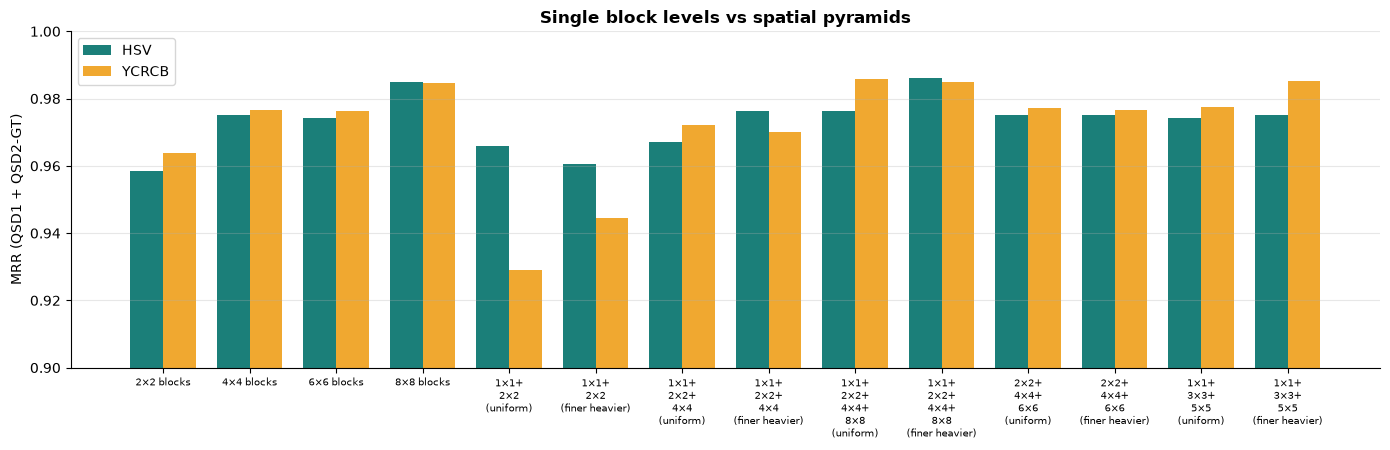

In [27]:
fig, ax = plt.subplots(figsize=(14, 4.6))
order = exp_pyr[exp_pyr.space == "HSV"][["layout", "weighting"]].apply(
    lambda r: r.layout.replace("pyramid ", "").replace("+", "+\n") + ("" if r.weighting == "-" else f"\n({r.weighting})"), axis=1).tolist()
xx = np.arange(len(order))
for k, (space, col) in enumerate(zip(["HSV", "YCRCB"], [TEAL, ORANGE])):
    ax.bar(xx + (k - 0.5) * 0.38, exp_pyr[exp_pyr.space == space]["MRR"], 0.38, color=col, label=space)
ax.set_xticks(xx, order, fontsize=7.5); ax.set_ylim(0.9, 1.0); ax.set_ylabel("MRR (QSD1 + QSD2-GT)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.set_title("Single block levels vs spatial pyramids")
plt.tight_layout(); savefig("pyramid_results"); plt.show()

**Result and conclusions**
- **The finest level is what matters.** Pyramids without a fine level, (1×1 + 2×2) or (1×1 + 2×2 + 4×4), are worse than
  8×8 blocks alone. Pyramids that include the 8×8 level (1+2+4+8) are as good as 8×8 blocks (MRR ≈ 0.985), not better.
- **Weighting:** giving more weight to the finer levels is better or equal in most of the pyramids (as in Lazebnik et al.),
  especially when the pyramid contains the coarse 1×1 level, but the differences are small (≤ 0.01 MRR).
- **Why no clear gain here:** the coarse levels are meant to tolerate misalignment, and on QSD1 / QSD2-GT the queries are
  *already aligned* with the database images (cropped painting vs cropped painting). We check again in §6, where the
  crops come from our own masks and are not perfectly aligned: there the pyramid does pay off.

### 3.6 Distances
**Why:** check that the best distance of week 1 is still the best with much bigger, sparser descriptors.

In [28]:
rows = []
for space, b, n in [("HSV", (4, 4, 4), 5), ("HSV", (12, 8, 8), 4), ("LAB", (8, 16, 16), 6), ("YCRCB", (6, 12, 12), 3)]:
    rows += run_config(space, "3d", b, SCHEME[space], levels=(n,), dists=tuple(DISTANCES))
exp_dist = pd.DataFrame(rows)
exp_dist["config"] = exp_dist.space + " " + exp_dist.bins + " " + exp_dist.levels
display(exp_dist.pivot_table(index="config", columns="dist", values="MRR").round(3))

dist,JS,L1,chi2,euclidean,hellinger
config,,,,,
"HSV (12, 8, 8) (4,)",0.986,0.979,0.987,0.720,0.986
"HSV (4, 4, 4) (5,)",0.988,0.989,0.988,0.868,0.987
"LAB (8, 16, 16) (6,)",0.977,0.977,0.969,0.769,0.977
"YCRCB (6, 12, 12) (3,)",0.985,0.969,0.985,0.849,0.985


**Result and conclusions:** χ² and Hellinger are again the best and very close; Jensen–Shannon is similar; L1 a bit worse;
**Euclidean is much worse** with block histograms (it is dominated by the few large bins and ignores small but distinctive
colours). We keep **Hellinger** (and χ² as an equivalent alternative).

## 4. Task 3 – Background removal using only colour

**The rule:** the mask must come from the **colour** of the background (model of the background distribution, colour
thresholds…). No contour or object detectors. We only use colour statistics, thresholds and morphological post-processing
of the binary mask.

**The key observation:** in every QSD2 photo the painting is in the middle and the **image border is wall**: the
organisers guarantee **at least 15 px of wall on every side** of the painting. So we learn the colour of the background
from the 15-px strip along the border of each image (taken at full resolution), and mark as painting every pixel
whose colour is far from that model. Each image gets its own model, so it adapts to the wall colour and the light of
every photo.

We compare three ways of modelling the background colour:

| Method | Background model | Decision |
|---|---|---|
| M1 – colour threshold | median colour of the border strip (Lab) | Euclidean distance in Lab > fixed T |
| M2 – Gaussian + Otsu | robust mean and covariance of the border strip (Lab) | Mahalanobis distance > threshold chosen **automatically per image with Otsu** |
| M3 – GMM | Gaussian mixture (wall + shadows + floor…) fitted to the border strip | log-likelihood lower than that of 99% of the border pixels |

- **Mahalanobis** distance = distance measured in units of the wall's own variation: if the wall varies a lot in brightness
  (light gradient) but little in hue, a change of hue counts much more than a change of brightness.
- **Robust estimate:** labels, plugs or a shadow can fall inside the strip, so it is not always 100% wall. We estimate the mean and the
  covariance with the 80% of border pixels closest to the median colour (the dominant colour = the wall).
- **Otsu** picks the threshold that best separates the histogram of distances into two classes (background / painting),
  so there is no fixed threshold to tune.

All masks are computed on a copy of the image with longest side 400 px (after a 5×5 median filter to remove texture noise)
and resized back to the original size.

In [29]:
WORK_SIDE = 400


BORDER_PX = 15   # the organisers guarantee at least 15 px of wall on every side of the painting


def border_mask(h, w, t):
    m = np.zeros((h, w), bool)
    m[:t], m[-t:], m[:, :t], m[:, -t:] = True, True, True, True
    return m


def border_pixels(img, t=BORDER_PX):
    """Lab pixels of the t-pixel strip along the 4 borders of the FULL-RESOLUTION image (guaranteed to be wall)."""
    lab = cv2.cvtColor(cv2.medianBlur(img, 5), cv2.COLOR_BGR2LAB)
    return lab[border_mask(*lab.shape[:2], t)].astype(np.float64)


def robust_gaussian(P, keep=0.8):
    """Mean / covariance of the dominant colour: the `keep` fraction of pixels closest to the median colour."""
    d = np.linalg.norm(P - np.median(P, 0), axis=1)
    Pk = P[d <= np.quantile(d, keep)]
    return Pk.mean(0), np.cov(Pk.T) + np.eye(P.shape[1])          # + I: regularisation for very flat walls


def mahalanobis_map(x, mu, cov):
    d = x.reshape(-1, x.shape[-1]).astype(np.float64) - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, np.linalg.inv(cov), d)).reshape(x.shape[:2])


def otsu_threshold(v, nbins=256):
    """Otsu's threshold for a float array: maximise the between-class variance."""
    hist, edges = np.histogram(v, nbins)
    p, c = hist / hist.sum(), (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(p); w1 = 1 - w0
    m0 = np.cumsum(p * c) / np.maximum(w0, 1e-12)
    m1 = ((p * c).sum() - np.cumsum(p * c)) / np.maximum(w1, 1e-12)
    return c[np.argmax(w0 * w1 * (m0 - m1) ** 2)]


def fg_threshold(lab, P, T=30):
    """M1: Euclidean Lab distance to the median border colour, fixed threshold."""
    d = np.linalg.norm(lab.astype(np.float64) - np.median(P, 0), axis=2)
    return d > T, d


def fg_gaussian(lab, P, keep=0.8, shadow=False, shadow_k=2.0):
    """M2: Mahalanobis distance to a robust Gaussian model of the wall; Otsu threshold on log(1 + distance)."""
    mu, cov = robust_gaussian(P, keep)
    ld = np.log1p(mahalanobis_map(lab, mu, cov))
    fg = ld > otsu_threshold(ld)
    if shadow:   # optional (tested in §4.3): darker pixels with the chroma of the wall are cast shadows -> background
        dc = mahalanobis_map(lab[..., 1:], mu[1:], cov[1:, 1:])
        fg &= ~((lab[..., 0] < mu[0]) & (dc < shadow_k))
    return fg, ld


def fg_gmm(lab, P, n=3):
    """M3: Gaussian mixture model of the border colours; background if as likely as 99% of the border pixels."""
    from sklearn.mixture import GaussianMixture
    Ps = P[np.random.default_rng(0).choice(len(P), min(len(P), 4000), replace=False)]
    g = GaussianMixture(n, covariance_type="full", reg_covar=1.0, random_state=0).fit(Ps)
    nll = -g.score_samples(lab.reshape(-1, 3).astype(np.float64)).reshape(lab.shape[:2])
    return nll > np.percentile(-g.score_samples(P), 99), nll

**Post-processing of the binary mask** (only morphology on the mask, no image contours):
1. **closing + opening** with a small square (2–3% of the image side): fill small gaps and remove isolated pixels;
2. keep the **largest connected component** (the painting; drops labels and small objects on the wall);
3. **fill holes**: wall-coloured areas *inside* the painting (e.g. a white sky) are part of the painting;
4. **row / column filling**: for every row (and every column) fill between the first and the last foreground pixel, and keep
   the intersection. A painting is a (slightly projected) rectangle, so this closes notches on its sides.

In [30]:
def largest_component(m):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    return m.astype(bool) if n <= 1 else lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])


def fill_holes(m):
    """Holes = background pixels that cannot be reached from the image border (flood fill from a corner of a padded copy)."""
    pad = cv2.copyMakeBorder(m.astype(np.uint8), 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    ff = pad.copy()
    cv2.floodFill(ff, np.zeros((pad.shape[0] + 2, pad.shape[1] + 2), np.uint8), (0, 0), 1)
    return m.astype(bool) | (ff == 0)[1:-1, 1:-1]


def row_col_fill(m):
    rows, cols = np.zeros_like(m, bool), np.zeros_like(m, bool)
    for y in np.where(m.any(1))[0]:
        xs = np.where(m[y])[0]; rows[y, xs[0]:xs[-1] + 1] = True
    for x in np.where(m.any(0))[0]:
        ys = np.where(m[:, x])[0]; cols[ys[0]:ys[-1] + 1, x] = True
    return rows & cols


def postprocess(fg, steps=("morph", "largest", "holes", "rowcol"), open_k=0.02, close_k=0.03):
    s = min(fg.shape)
    se = lambda f: cv2.getStructuringElement(cv2.MORPH_RECT, (max(1, int(f * s)) | 1,) * 2)
    m = fg.astype(np.uint8)
    if "morph" in steps:
        m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, se(close_k)), cv2.MORPH_OPEN, se(open_k))
    if "largest" in steps: m = largest_component(m)
    if "holes" in steps:   m = fill_holes(m)
    if "rowcol" in steps:  m = row_col_fill(m)
    return m.astype(bool)


FG_METHODS = {"M1 threshold": fg_threshold, "M2 gaussian+otsu": fg_gaussian, "M3 gmm": fg_gmm}


def compute_mask(img, method="M2 gaussian+otsu", steps=("morph", "largest", "holes", "rowcol"), return_steps=False,
                 border_px=BORDER_PX, **kw):
    """Full-resolution BGR image -> boolean mask of the painting (same size as the image)."""
    H, W = img.shape[:2]
    small = cv2.medianBlur(resize_max(img, WORK_SIDE), 5)
    lab = cv2.cvtColor(small, cv2.COLOR_BGR2LAB)
    P = border_pixels(img, border_px)          # wall samples taken at full resolution, not on the 400 px image
    fg, score = FG_METHODS[method](lab, P, **kw)
    m = postprocess(fg, steps)
    if not m.any():                            # nothing found: keep the whole image rather than crash later
        m[:] = True
    full = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST).astype(bool)
    t_small = max(1, int(round(border_px * small.shape[0] / H)))
    strip = border_mask(*small.shape[:2], t_small)
    return (full, dict(small=small, score=score, raw=fg, post=m, strip=strip)) if return_steps else full

### 4.1 The method step by step on one image

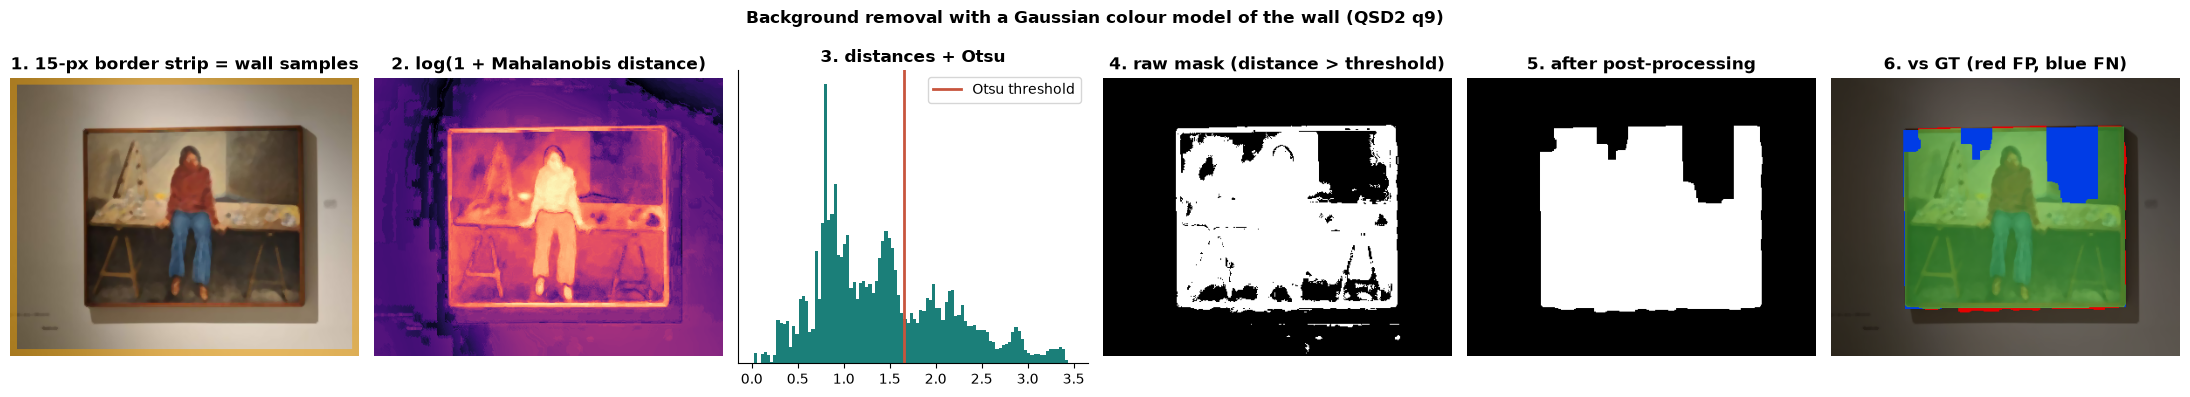

In [31]:
i = 9
mask, st = compute_mask(QSD2_FULL[i], return_steps=True)
bstrip = st["strip"]
gt_small = cv2.resize(QSD2_GTMASK[i].astype(np.uint8), st["small"].shape[1::-1], interpolation=cv2.INTER_NEAREST) > 0


def error_overlay(img, pred, gt):
    """Green = correct painting, red = false positive (wall taken as painting), blue = false negative (painting missed)."""
    out = (img.astype(np.float32) * 0.45).astype(np.uint8)
    out[pred & gt] = (img[pred & gt] * 0.5 + np.array([60, 200, 60]) * 0.5).astype(np.uint8)
    out[pred & ~gt] = (0, 0, 230); out[~pred & gt] = (230, 60, 0)
    return out


fig, axes = plt.subplots(1, 6, figsize=(22, 4))
show_img = st["small"].copy(); show_img[bstrip] = (0.5 * show_img[bstrip] + [0, 80, 120]).astype(np.uint8)
axes[0].imshow(show_img[..., ::-1]); axes[0].set_title(f"1. {BORDER_PX}-px border strip = wall samples")
im = axes[1].imshow(st["score"], cmap="magma"); axes[1].set_title("2. log(1 + Mahalanobis distance)")
axes[2].hist(st["score"].ravel(), 100, color=TEAL); axes[2].axvline(otsu_threshold(st["score"]), color=RED, lw=2, label="Otsu threshold")
axes[2].set_title("3. distances + Otsu"); axes[2].legend(); axes[2].set_yticks([])
axes[3].imshow(st["raw"], cmap="gray"); axes[3].set_title("4. raw mask (distance > threshold)")
axes[4].imshow(st["post"], cmap="gray"); axes[4].set_title("5. after post-processing")
axes[5].imshow(error_overlay(st["small"], st["post"], gt_small)[..., ::-1]); axes[5].set_title("6. vs GT (red FP, blue FN)")
for a in axes[[0, 1, 3, 4, 5]]: a.axis("off")
plt.suptitle(f"Background removal with a Gaussian colour model of the wall (QSD2 q{i})", fontweight="bold"); plt.tight_layout(); savefig("bg_steps"); plt.show()

## 5. Task 4 – Evaluation of the masks: precision, recall, F1

For every image, comparing our mask (O) with the annotation (A) pixel by pixel:
- TP = A & O, FP = ¬A & O (wall marked as painting), FN = A & ¬O (painting lost);
- **precision** = TP / (TP + FP): how much of what we kept is painting;
- **recall** = TP / (TP + FN): how much of the painting we kept;
- **F1** = 2PR / (P + R).

We report the **mean over the 30 images** (every image counts the same) and also the minimum F1, to see the worst case.

In [32]:
def prf(pred, gt):
    tp = np.sum(pred & gt); fp = np.sum(pred & ~gt); fn = np.sum(~pred & gt)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def eval_masks(name, **kw):
    t = time.time()
    masks = [compute_mask(im, **kw) for im in QSD2_FULL]
    R = np.array([prf(m, g) for m, g in zip(masks, QSD2_GTMASK)])
    return dict(method=name, precision=R[:, 0].mean(), recall=R[:, 1].mean(), F1=R[:, 2].mean(), F1_min=R[:, 2].min(),
                worst=int(R[:, 2].argmin()), s_per_img=(time.time() - t) / len(masks)), R, masks

### 5.1 Comparison of the three background models
**Why:** check whether a richer model of the background (a single Gaussian or a mixture) is better than a single colour with a
fixed threshold, and whether the automatic per-image threshold (Otsu) is better than a fixed one.

In [33]:
rows, per_image, all_masks = [], {}, {}
for T in [15, 25, 35]:
    r, R, M = eval_masks(f"M1 threshold T={T}", method="M1 threshold", T=T); rows.append(r)
r, R, M = eval_masks("M2 gaussian+otsu", method="M2 gaussian+otsu"); rows.append(r); per_image["M2"] = R; all_masks["M2"] = M
try:
    r, R, M = eval_masks("M3 gmm (3 components)", method="M3 gmm"); rows.append(r)
except ImportError:
    print("scikit-learn not installed: M3 skipped")
exp_bg = pd.DataFrame(rows)
display(exp_bg.round(3))

,method,precision,recall,F1,F1_min,worst,s_per_img
0,M1 threshold T=15,0.689,0.996,0.806,0.576,29,0.021
1,M1 threshold T=25,0.788,0.981,0.863,0.654,29,0.021
2,M1 threshold T=35,0.843,0.919,0.868,0.193,29,0.021
3,M2 gaussian+otsu,0.953,0.963,0.954,0.647,20,0.030
4,M3 gmm (3 components),0.885,0.983,0.927,0.697,20,0.448


**Result and conclusions**
- **M1 (one colour + fixed threshold)** has a high recall but a poor precision: a fixed threshold cannot fit every photo
  (walls with a light gradient, shadows), and a threshold that is good for one image is bad for another.
- **M2 (Gaussian + Mahalanobis + Otsu)** is the best: **F1 ≈ 0.96**. Mahalanobis accounts for how much the wall varies in
  each direction of the colour space, and Otsu adapts the threshold to each image.
- **M3 (GMM)** is worse (lower precision) and ~25× slower: the mixture fits the border pixels very tightly, so wall pixels that
  are a bit different from the border (shadows, the light gradient towards the centre) fall outside the model and are
  marked as painting. We keep **M2**.

### 5.2 Ablation: what does each part of M2 contribute?
**Why:** to justify every step (and to check that the result does not depend on a lucky parameter).

In [34]:
rows = []
for name, kw in [("no post-processing", dict(steps=())),
                 ("+ morphology", dict(steps=("morph",))),
                 ("+ largest component", dict(steps=("morph", "largest"))),
                 ("+ fill holes", dict(steps=("morph", "largest", "holes"))),
                 ("+ row/column fill (= M2)", dict()),
                 ("border strip 5 px", dict(border_px=5)), ("border strip 10 px", dict(border_px=10)),
                 ("robust keep 70%", dict(keep=0.7)), ("robust keep 90%", dict(keep=0.9)), ("no robust estimate (100%)", dict(keep=1.0)),
                 ("+ shadow rule", dict(shadow=True))]:
    rows.append(eval_masks(name, method="M2 gaussian+otsu", **kw)[0])
exp_ablation = pd.DataFrame(rows)
display(exp_ablation.drop(columns="s_per_img").round(3))

,method,precision,recall,F1,F1_min,worst
0,no post-processing,0.942,0.889,0.910,0.540,20
1,+ morphology,0.942,0.919,0.926,0.605,20
2,+ largest component,0.944,0.909,0.917,0.329,29
3,+ fill holes,0.953,0.958,0.951,0.646,20
4,+ row/column fill (= M2),0.953,0.963,0.954,0.647,20
5,border strip 5 px,0.942,0.964,0.947,0.647,20
6,border strip 10 px,0.954,0.963,0.955,0.655,20
7,robust keep 70%,0.942,0.968,0.950,0.680,20
8,robust keep 90%,0.957,0.962,0.955,0.633,20
9,no robust estimate (100%),0.960,0.959,0.955,0.610,20


**Result and conclusions**
- **Post-processing matters a lot**: the raw thresholded mask has many isolated pixels (texture, labels on the wall) and
  holes (wall-coloured parts of the painting). Keeping the largest component and filling holes fixes most of them.
- **Filling holes is the single most useful step** (+0.03 F1): many paintings have wall-coloured areas inside (light skies,
  white passe-partouts) that the colour model marks as background.
- The method is **stable**: border strip 5–15 px and robust fraction 70–100% all give F1 = 0.950–0.957. The robust estimate
  barely changes the mean, but it improves the worst image (min F1 0.604 → 0.654): it only matters for the few paintings
  that touch the border. With so few differences we keep the default values (15-px strip, 80% robust fraction).
- **Shadow rule** (darker pixels with the chroma of the wall are background): it removes some cast shadows (precision
  0.953 → 0.959), but it also deletes parts of dark, neutral-coloured paintings (recall 0.966 → 0.954) and the mean F1 does
  not improve. **Not used.**

### 5.3 Per-image results: where does it fail?

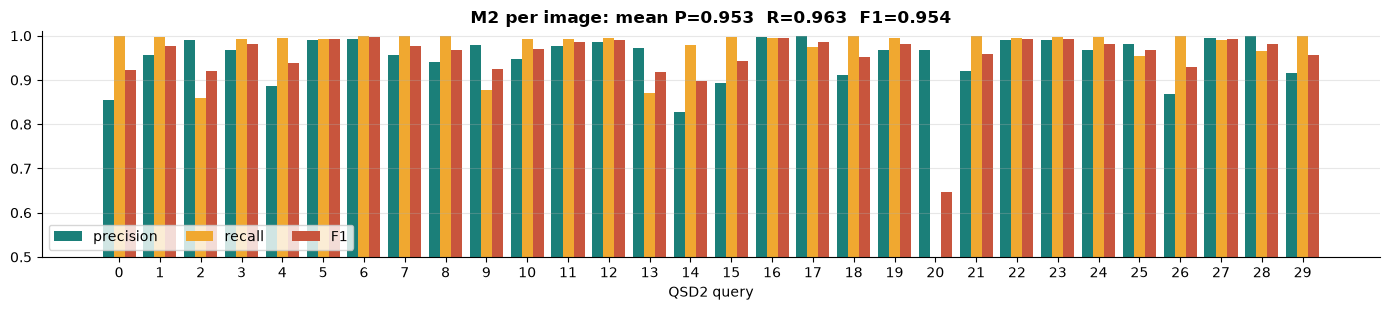

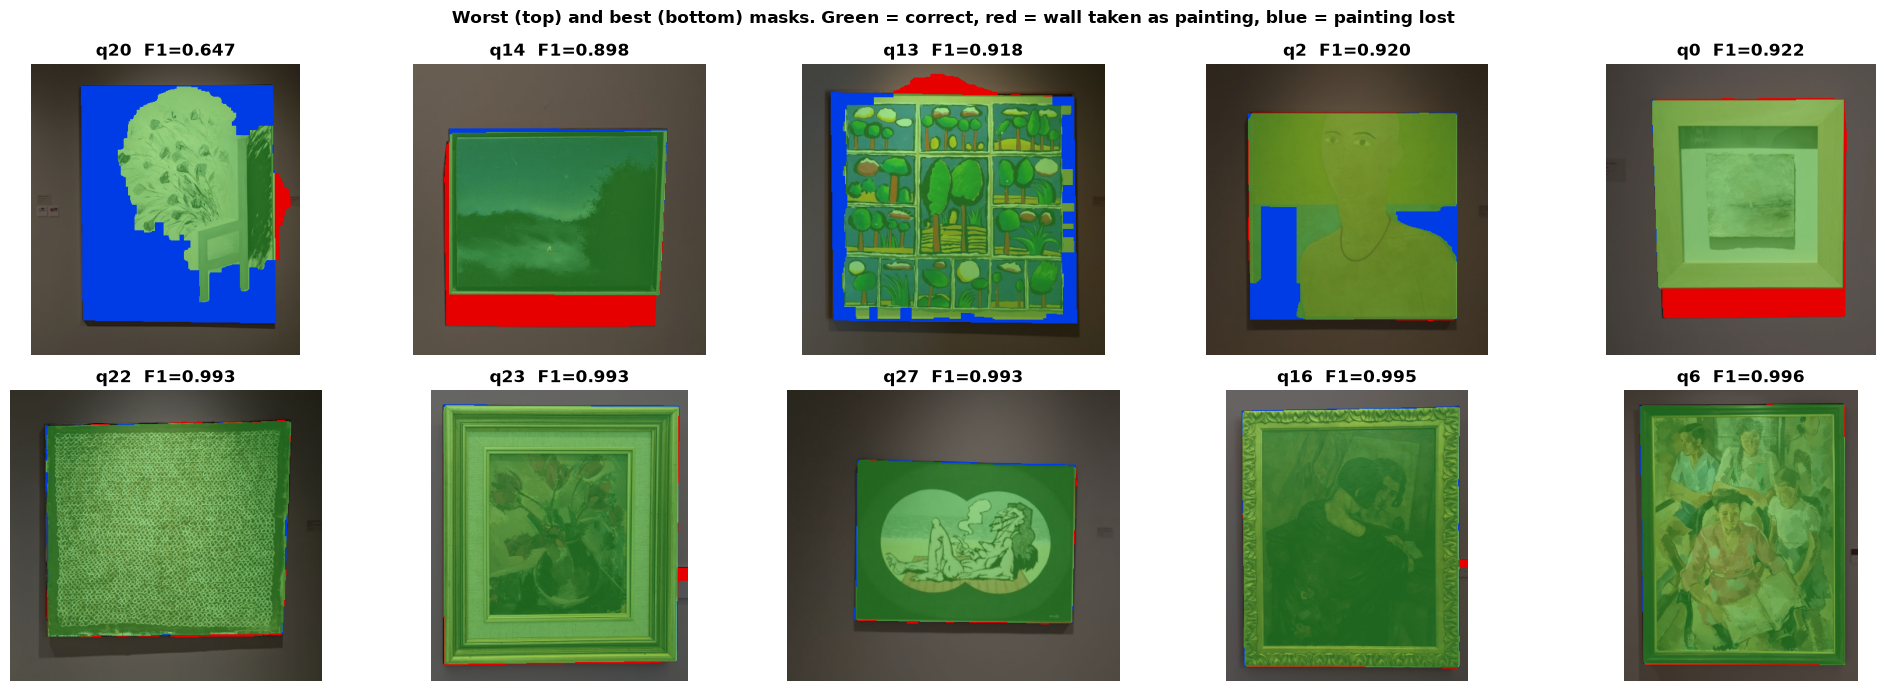

In [35]:
R = per_image["M2"]
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.bar(np.arange(30) - 0.27, R[:, 0], 0.27, color=TEAL, label="precision")
ax.bar(np.arange(30), R[:, 1], 0.27, color=ORANGE, label="recall")
ax.bar(np.arange(30) + 0.27, R[:, 2], 0.27, color=RED, label="F1")
ax.set_ylim(0.5, 1.01); ax.set_xticks(range(30)); ax.set_xlabel("QSD2 query"); ax.legend(ncol=3, loc="lower left"); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"M2 per image: mean P={R[:, 0].mean():.3f}  R={R[:, 1].mean():.3f}  F1={R[:, 2].mean():.3f}")
plt.tight_layout(); savefig("bg_per_image"); plt.show()

order = np.argsort(R[:, 2])
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, i in zip(axes.ravel(), list(order[:5]) + list(order[-5:])):
    small = resize_max(QSD2_FULL[i], 400)
    sz = small.shape[1::-1]
    pm = cv2.resize(all_masks["M2"][i].astype(np.uint8), sz, interpolation=cv2.INTER_NEAREST) > 0
    gm = cv2.resize(QSD2_GTMASK[i].astype(np.uint8), sz, interpolation=cv2.INTER_NEAREST) > 0
    ax.imshow(error_overlay(small, pm, gm)[..., ::-1]); ax.set_title(f"q{i}  F1={R[i, 2]:.3f}"); ax.axis("off")
axes[0, 0].set_ylabel("worst 5"); axes[1, 0].set_ylabel("best 5")
plt.suptitle("Worst (top) and best (bottom) masks. Green = correct, red = wall taken as painting, blue = painting lost", fontweight="bold")
plt.tight_layout(); savefig("bg_best_worst"); plt.show()

**Error analysis**
- **Cast shadows** below / beside the painting (red strips): the shadow is a darker version of the wall, far enough from
  the wall model to be taken as painting.
- **White painting on a white wall** (q20) and **light areas touching the frame** (q9): the painting has the colour of the
  wall, so a colour-only method cannot separate them. This is the limit of the "just colour" rule.
- Paintings whose frame touches the image border are handled well thanks to the robust estimate.

## 6. Task 5 – Retrieval on QSD2: remove the background, then retrieve

Pipeline for every QSD2 image: **mask (M2) → crop the bounding box of the mask → descriptor → ranking**. We crop instead of
computing the histogram with the mask on the full image because the block grid must be aligned with the painting, as in
the BBDD images (which are crops of the painting with its frame).

Now we have a third validation set, **QSD2-pred**: the QSD2 paintings cropped with **our** masks. The difference between
QSD2-GT and QSD2-pred is exactly the cost of our segmentation errors.

In [36]:
QSD2_MASKS = all_masks["M2"]                                        # our masks (computed in §5.1)
QSD2_PREDCROP = [resize_max(bbox_crop(im, m)) for im, m in zip(QSD2_FULL, QSD2_MASKS)]
SETS["QSD2-pred"] = (QSD2_PREDCROP, GT2)
ALL3 = ("QSD1", "QSD2-GT", "QSD2-pred")

CANDIDATES = {                       # the best configurations of §3 (name: space, bins, levels, level weights)
    "HSV 4x4x4, 5x5 blocks": ("HSV", (4, 4, 4), (5,), None),
    "HSV 8x6x6, 5x5 blocks": ("HSV", (8, 6, 6), (5,), None),
    "HSV 8x6x6, pyramid 1-2-4-8": ("HSV", (8, 6, 6), (1, 2, 4, 8), [1, 2, 4, 8]),
    "Lab 8x16x16, 6x6 blocks": ("LAB", (8, 16, 16), (6,), None),
    "YCrCb 6x12x12, 6x6 blocks": ("YCRCB", (6, 12, 12), (6,), None),
    "YCrCb 6x12x12, pyramid 1-2-4-8": ("YCRCB", (6, 12, 12), (1, 2, 4, 8), [1, 2, 4, 8]),
}


def run_named(name, margin=0.0, dists=("hellinger",), sets=ALL3, keep_pos=False):
    space, bins, levels, weights = CANDIDATES[name]
    return [dict(r, config=name) for r in run_config(space, "3d", bins, SCHEME[space], levels, weights, margin, dists, sets, keep_pos)]


t0 = time.time()
exp_t5 = pd.DataFrame([r for name in CANDIDATES for r in run_named(name, keep_pos=True)])
print(f"{time.time() - t0:.0f}s")
display(exp_t5[["config", "QSD1 mAP@1", "QSD2-GT mAP@1", "QSD2-GT mAP@5", "QSD2-pred mAP@1", "QSD2-pred mAP@5", "QSD2-pred MRR"]].round(3))

15s


,config,QSD1 mAP@1,QSD2-GT mAP@1,QSD2-GT mAP@5,QSD2-pred mAP@1,QSD2-pred mAP@5,QSD2-pred MRR
0,"HSV 4x4x4, 5x5 blocks",0.967,1.000,1.000,0.833,0.873,0.882
1,"HSV 8x6x6, 5x5 blocks",0.967,0.967,0.978,0.933,0.942,0.946
2,"HSV 8x6x6, pyramid 1-2-4-8",0.967,1.000,1.000,0.900,0.917,0.921
3,"Lab 8x16x16, 6x6 blocks",0.967,0.967,0.983,0.900,0.907,0.913
4,"YCrCb 6x12x12, 6x6 blocks",0.967,0.967,0.983,0.900,0.917,0.921
5,"YCrCb 6x12x12, pyramid 1-2-4-8",0.967,1.000,1.000,0.867,0.900,0.904


**Result:** with our masks the retrieval on QSD2 drops by a few queries with respect to the perfect crops. Let us see why.

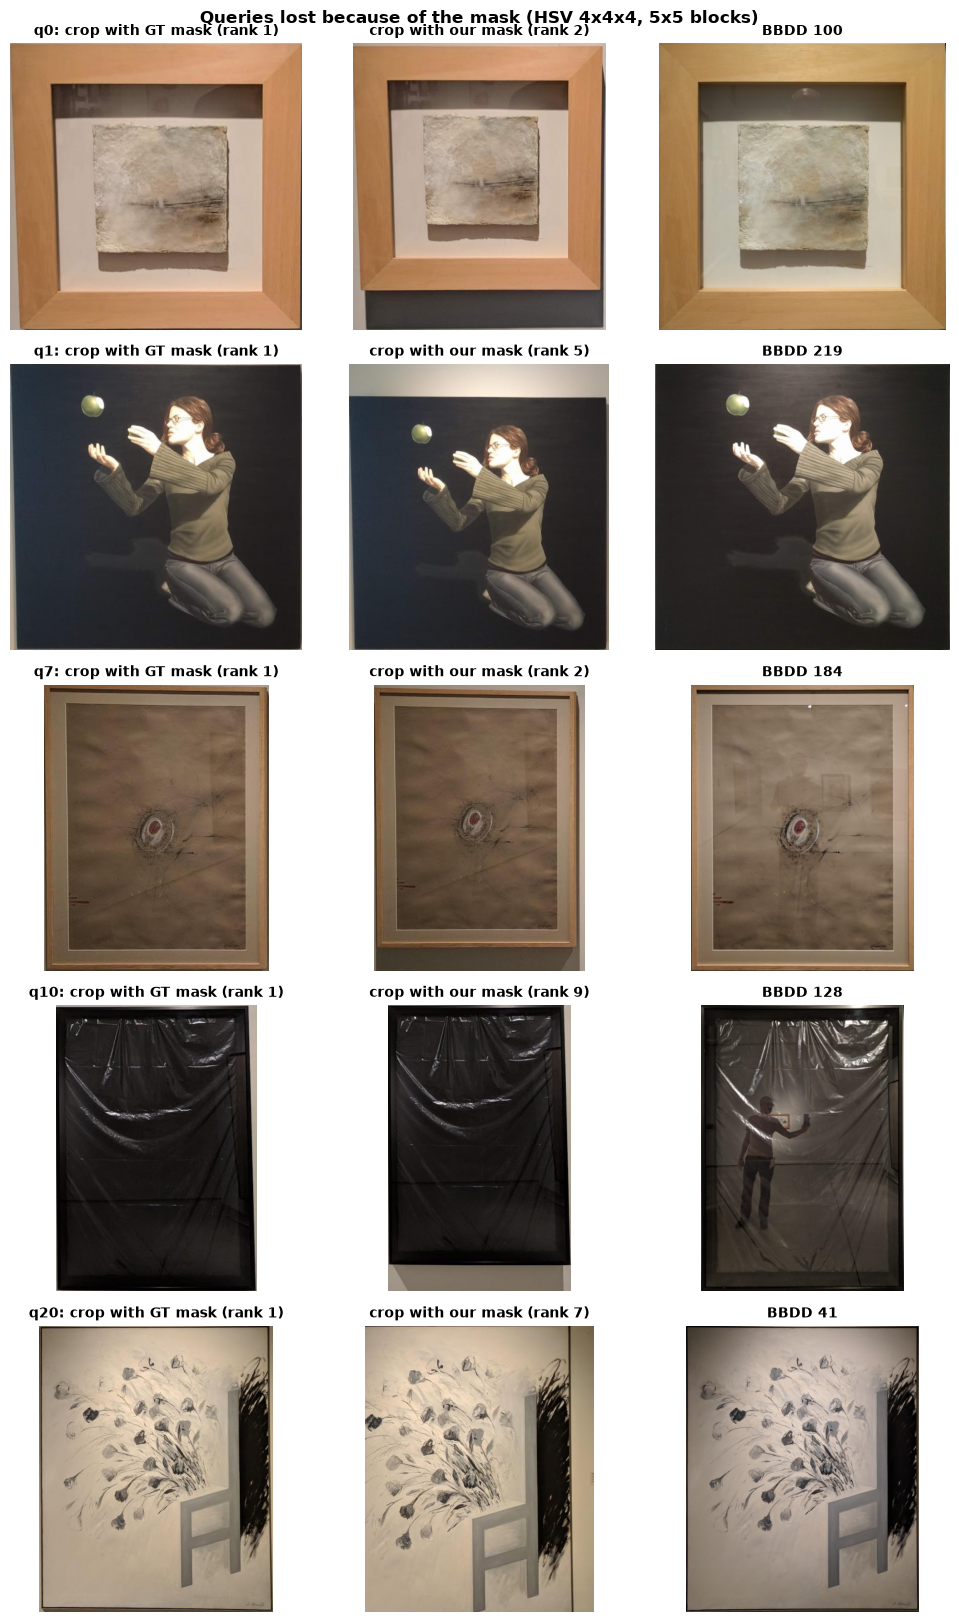

In [37]:
r0 = exp_t5.iloc[0]
lost = [i for i in range(30) if r0["QSD2-pred pos"][i] > 1 and r0["QSD2-GT pos"][i] == 1]
fig, axes = plt.subplots(len(lost), 3, figsize=(10, 3.3 * len(lost)), squeeze=False)
for row, i in zip(axes, lost):
    for ax, (img, title) in zip(row, [(QSD2_GTCROP[i], f"q{i}: crop with GT mask (rank 1)"),
                                      (QSD2_PREDCROP[i], f"crop with our mask (rank {r0['QSD2-pred pos'][i]})"),
                                      (BBDD[BBDD_IDS.index(GT2[i][0])], f"BBDD {GT2[i][0]}")]):
        ax.imshow(img[..., ::-1]); ax.set_title(title, fontsize=10); ax.axis("off")
plt.suptitle(f"Queries lost because of the mask ({r0['config']})", fontweight="bold"); plt.tight_layout(); savefig("t5_lost"); plt.show()

**Why they fail:** the masks are good (F1 > 0.9), but they include a thin strip of wall or shadow above or below the
painting. Two things then go wrong:
1. the **illumination normalisation** uses the mean of the whole crop, and a strip of bright wall next to a dark painting
   changes that mean a lot;
2. the **block grid** is shifted, and the top / bottom blocks contain wall instead of painting.

### 6.1 Making the descriptor robust to imperfect crops: inner margin
**Why:** if we ignore a small band along the border of *every* image (queries and BBDD alike), a few % of wall or shadow
in the query crop is cut away before the normalisation and the blocks are computed. Week 1 showed that removing a lot
of the image (the frame) hurts, so we test small margins.

In [38]:
t0 = time.time()
MARGINS = [0.0, 0.03, 0.05, 0.08, 0.12]
exp_margin = pd.DataFrame([r for name in CANDIDATES for m in MARGINS for r in run_named(name, margin=m)])
print(f"{time.time() - t0:.0f}s")
display(exp_margin.pivot_table(index="config", columns="margin", values="QSD2-pred mAP@1").round(3))
display(exp_margin.pivot_table(index="config", columns="margin", values="QSD1 mAP@1").round(3))

91s


margin,0.00,0.03,0.05,0.08,0.12
config,,,,,
"HSV 4x4x4, 5x5 blocks",0.833,0.900,0.900,0.900,0.933
"HSV 8x6x6, 5x5 blocks",0.933,0.900,0.933,0.967,0.900
"HSV 8x6x6, pyramid 1-2-4-8",0.900,0.900,0.900,0.900,0.933
"Lab 8x16x16, 6x6 blocks",0.900,0.867,0.933,0.933,0.933
"YCrCb 6x12x12, 6x6 blocks",0.900,0.900,1.000,0.933,0.933
"YCrCb 6x12x12, pyramid 1-2-4-8",0.867,0.967,1.000,1.000,0.967


margin,0.00,0.03,0.05,0.08,0.12
config,,,,,
"HSV 4x4x4, 5x5 blocks",0.967,0.967,0.967,0.900,0.900
"HSV 8x6x6, 5x5 blocks",0.967,0.967,0.967,0.933,0.900
"HSV 8x6x6, pyramid 1-2-4-8",0.967,0.967,0.967,0.933,0.933
"Lab 8x16x16, 6x6 blocks",0.967,0.967,0.967,0.900,0.900
"YCrCb 6x12x12, 6x6 blocks",0.967,0.967,0.967,0.933,0.933
"YCrCb 6x12x12, pyramid 1-2-4-8",0.967,0.967,0.967,0.933,0.933


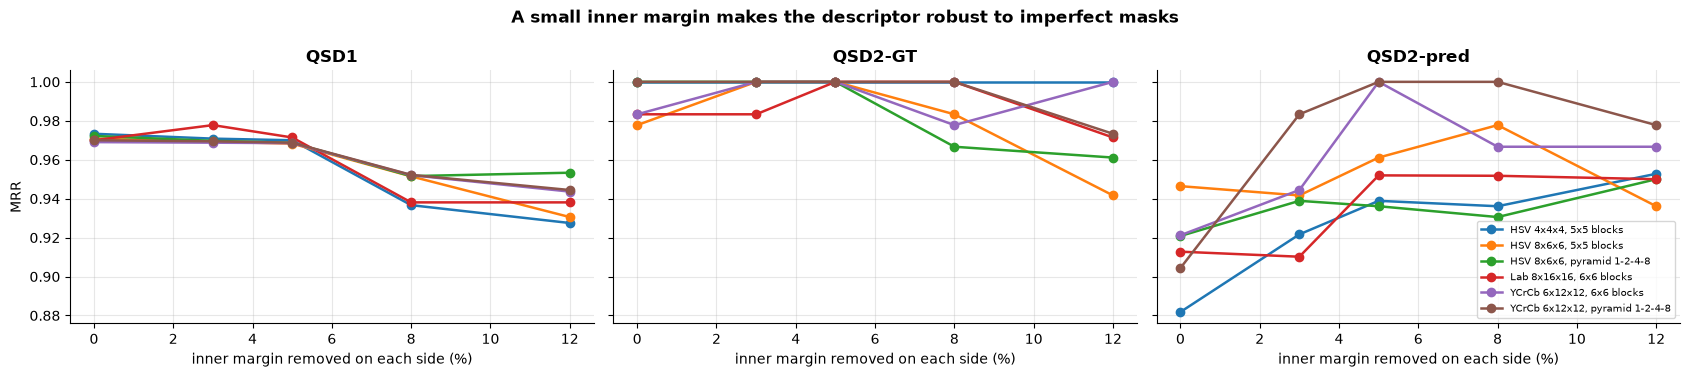

,QSD1 MRR,QSD2-GT MRR,QSD2-pred MRR
margin,,,
0.00,0.971,0.991,0.915
0.03,0.971,0.997,0.940
0.05,0.969,1.000,0.965
0.08,0.947,0.988,0.960
0.12,0.940,0.975,0.956


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, s in zip(axes, ALL3):
    for k, name in enumerate(CANDIDATES):
        d = exp_margin[exp_margin.config == name]
        ax.plot(d.margin * 100, d[f"{s} MRR"], "o-", lw=1.8, label=name, color=plt.cm.tab10(k))
    ax.set_title(s); ax.set_xlabel("inner margin removed on each side (%)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("MRR"); axes[2].legend(fontsize=7.5, loc="lower right")
plt.suptitle("A small inner margin makes the descriptor robust to imperfect masks", fontweight="bold"); plt.tight_layout(); savefig("margin"); plt.show()

display(exp_margin.groupby("margin")[[f"{s} MRR" for s in ALL3]].mean().round(3))

**Result and conclusions**
- **A 5% inner margin raises the mean MRR on QSD2-pred from 0.915 to 0.959** (it removes most of the wall / shadow strips
  left by the mask) while QSD1 and QSD2-GT stay at their best values.
- **8% or more starts to hurt QSD1 and QSD2-GT**: the frame and the outer part of the painting are part of its signature
  (the same conclusion as the frame-cropping experiment of week 1). **We use 5%.**
- **Here the spatial pyramid pays off:** with imperfect crops, *YCrCb 6×12×12 with the pyramid 1+2+4+8* is the most robust
  configuration (QSD2-pred mAP@1 0.967 with 3–5% margin and 1.000 with 8%), better than the same histogram with 6×6 blocks
  only. The coarse levels tolerate the small shifts of the block grid caused by the mask errors, which is exactly what the
  theory predicts and what we could not see with perfect crops in §3.5.

## 6.2 The final methods

**How we choose.** Many configurations are within one query of each other, so we do not pick "the cell with the highest
number". We pick configurations that are (a) at the top on **all three** sets, including QSD2-pred, which is the real
pipeline of Task 5, (b) in a **flat region** of the experiments (their neighbours with other bins / blocks / margins are
also good, so the choice is not luck), and (c) in **different colour spaces**, so that we can compare two different
descriptors. **Only method1 is submitted** (the week-2 instructions ask for a single method); method2 is the alternative
we compare it with.

- **method1 – YCrCb 3D 6×12×12 (range-adapted bins), spatial pyramid 1×1 + 2×2 + 4×4 + 8×8 (weights 1:2:4:8), Hellinger,
  5% inner margin.** The most robust configuration on QSD2-pred (§6.1), one of the two best families in the block experiment (§3.4) and it uses the three ideas of Task 1 (3D histogram, adapted bins, hierarchical histogram).
- **method2 – HSV 3D 8×6×6 (uniform bins), 5×5 blocks, Hellinger, 5% inner margin.** A different colour space with a
  simple block histogram; HSV with blocks is the most stable family across bins and blocks in §3.4 (all its
  configurations from 4×4 blocks on are within 0.02 MRR) and its descriptor is 10× smaller.

In [40]:
FINAL = {
    "method1": dict(name="YCrCb 3D 6x12x12 (range bins), pyramid 1-2-4-8, Hellinger", space="YCRCB", bins=(6, 12, 12),
                    levels=(1, 2, 4, 8), weights=[1, 2, 4, 8], dist="hellinger", margin=0.05),
    "method2": dict(name="HSV 3D 8x6x6, 5x5 blocks, Hellinger", space="HSV", bins=(8, 6, 6),
                    levels=(5,), weights=None, dist="hellinger", margin=0.05),
}
for m in FINAL.values():
    m["scheme"] = SCHEME[m["space"]]
    m["edges"] = make_edges(m["space"], m["bins"], m["scheme"], bbdd_pixels(m["space"], margin=m["margin"]) if m["scheme"] != "uniform" else None)


def describe_final(img, m):
    return describe(img, m["space"], "3d", m["edges"], m["levels"], m["weights"], m["margin"])


FINAL_DB = {k: np.stack([describe_final(x, m) for x in BBDD]) for k, m in FINAL.items()}


def bootstrap_ci(pos, k=1, n=2000, seed=0):
    """95% confidence interval of mAP@k by resampling the queries with replacement."""
    rng = np.random.default_rng(seed)
    ap = np.where(np.asarray(pos) <= k, 1.0 / np.asarray(pos), 0.0)
    boots = [ap[rng.integers(0, len(ap), len(ap))].mean() for _ in range(n)]
    return np.percentile(boots, [2.5, 97.5])


final_rows, final_pos = [], {}
for key, m in FINAL.items():
    for s in ALL3:
        imgs, gt = SETS[s]
        r = evaluate(np.stack([describe_final(x, m) for x in imgs]), FINAL_DB[key], gt, m["dist"])
        lo, hi = bootstrap_ci(r["pos"], 5)
        final_rows.append(dict(method=key, descriptor=m["name"], set=s, **{"mAP@1": r["map1"], "mAP@5": r["map5"], "MRR": r["mrr"]},
                               **{"mAP@5 95% CI": f"[{lo:.2f}, {hi:.2f}]", "wrong at rank 1": [i for i, p in enumerate(r["pos"]) if p > 1]}))
        final_pos[(key, s)] = r["pos"]
final_df = pd.DataFrame(final_rows)
display(final_df.round(3))

,method,descriptor,set,mAP@1,mAP@5,MRR,mAP@5 95% CI,wrong at rank 1
0,method1,"YCrCb 3D 6x12x12 (range bins), pyramid 1-2-4-8...",QSD1,0.967,0.967,0.969,"[0.90, 1.00]",[26]
1,method1,"YCrCb 3D 6x12x12 (range bins), pyramid 1-2-4-8...",QSD2-GT,1.000,1.000,1.000,"[1.00, 1.00]",[]
2,method1,"YCrCb 3D 6x12x12 (range bins), pyramid 1-2-4-8...",QSD2-pred,1.000,1.000,1.000,"[1.00, 1.00]",[]
3,method2,"HSV 3D 8x6x6, 5x5 blocks, Hellinger",QSD1,0.967,0.967,0.968,"[0.90, 1.00]",[26]
4,method2,"HSV 3D 8x6x6, 5x5 blocks, Hellinger",QSD2-GT,1.000,1.000,1.000,"[1.00, 1.00]",[]
5,method2,"HSV 3D 8x6x6, 5x5 blocks, Hellinger",QSD2-pred,0.933,0.961,0.961,"[0.91, 1.00]","[14, 29]"


## 6.3 Task 2 – QSD1-W2: week 2 vs week 1
The dev set is the same as in week 1, so the comparison is direct. We also show QSD2-GT, which tells us how well each
descriptor generalises to other photos.

,QSD1 (mAP@1 / mAP@5),QSD2-GT (mAP@1 / mAP@5),QSD2-pred (mAP@1 / mAP@5)
method,,,
"W1 method 1 (HSV 1D 16, χ²)",0.900 / 0.950,0.567 / 0.638,0.467 / 0.561
"W1 method 2 (Lab 1D 32, Hellinger)",0.900 / 0.922,0.700 / 0.754,0.533 / 0.631
W2 method1 (YCrCb 3D pyramid),0.967 / 0.967,1.000 / 1.000,1.000 / 1.000
W2 method2 (HSV 3D blocks),0.967 / 0.967,1.000 / 1.000,0.933 / 0.961


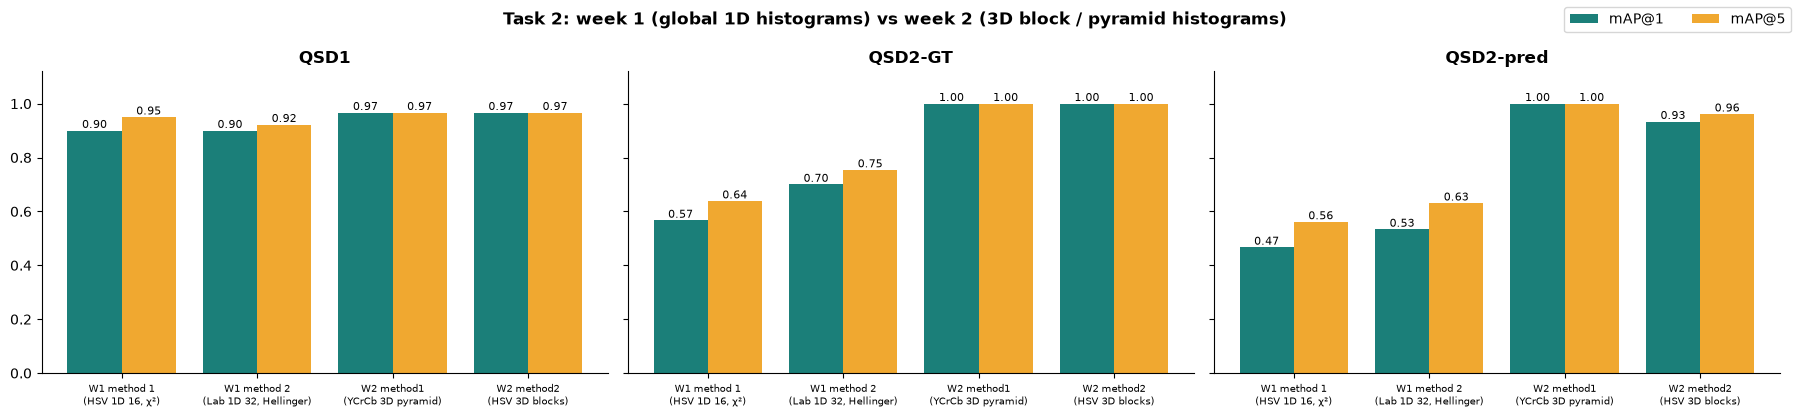

In [41]:
cmp_rows = []
for label, space, kind, bins, levels, dist, margin in [("W1 method 1 (HSV 1D 16, χ²)", "HSV", "1d", 16, (1,), "chi2", 0.0),
                                                        ("W1 method 2 (Lab 1D 32, Hellinger)", "LAB", "1d", 32, (1,), "hellinger", 0.0)]:
    r = run_config(space, kind, bins, "uniform", levels, None, margin, (dist,), ALL3)[0]
    cmp_rows.append(dict(method=label, **{s: (r[f"{s} mAP@1"], r[f"{s} mAP@5"]) for s in ALL3}))
for key, m in FINAL.items():
    d = final_df[final_df.method == key].set_index("set")
    short = "YCrCb 3D pyramid" if m["space"] == "YCRCB" else f"{m['space']} 3D blocks"
    cmp_rows.append(dict(method=f"W2 {key} ({short})", **{s: (d.loc[s, "mAP@1"], d.loc[s, "mAP@5"]) for s in ALL3}))
cmp = pd.DataFrame(cmp_rows).set_index("method")
display(cmp.map(lambda v: f"{v[0]:.3f} / {v[1]:.3f}").rename(columns=lambda c: f"{c}  (mAP@1 / mAP@5)"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, s in zip(axes, ALL3):
    vals1 = [v[0] for v in cmp[s]]; vals5 = [v[1] for v in cmp[s]]
    xx = np.arange(len(cmp))
    b1 = ax.bar(xx - 0.2, vals1, 0.4, color=TEAL, label="mAP@1"); b5 = ax.bar(xx + 0.2, vals5, 0.4, color=ORANGE, label="mAP@5")
    ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b5, fmt="%.2f", fontsize=8)
    ax.set_xticks(xx, [n.replace(" (", "\n(") for n in cmp.index], fontsize=7.5); ax.set_title(s); ax.set_ylim(0, 1.12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2)
plt.suptitle("Task 2: week 1 (global 1D histograms) vs week 2 (3D block / pyramid histograms)", fontweight="bold")
plt.tight_layout(); savefig("task2_w1_vs_w2"); plt.show()

**Result (Task 2):** on QSD1 (the same dev set as week 1) the best mAP@1 goes from **0.90 to 0.97** and mAP@5 from 0.95
to 0.97; the only query that is still wrong is q26 (below). The improvement is much larger on the photos of QSD2: from
0.57–0.70 to **1.00** with perfect crops and from 0.50–0.53 to **0.93–0.97** with our own masks. The week-1 descriptors
only worked on QSD1; the new ones generalise.

### 6.4 The remaining errors

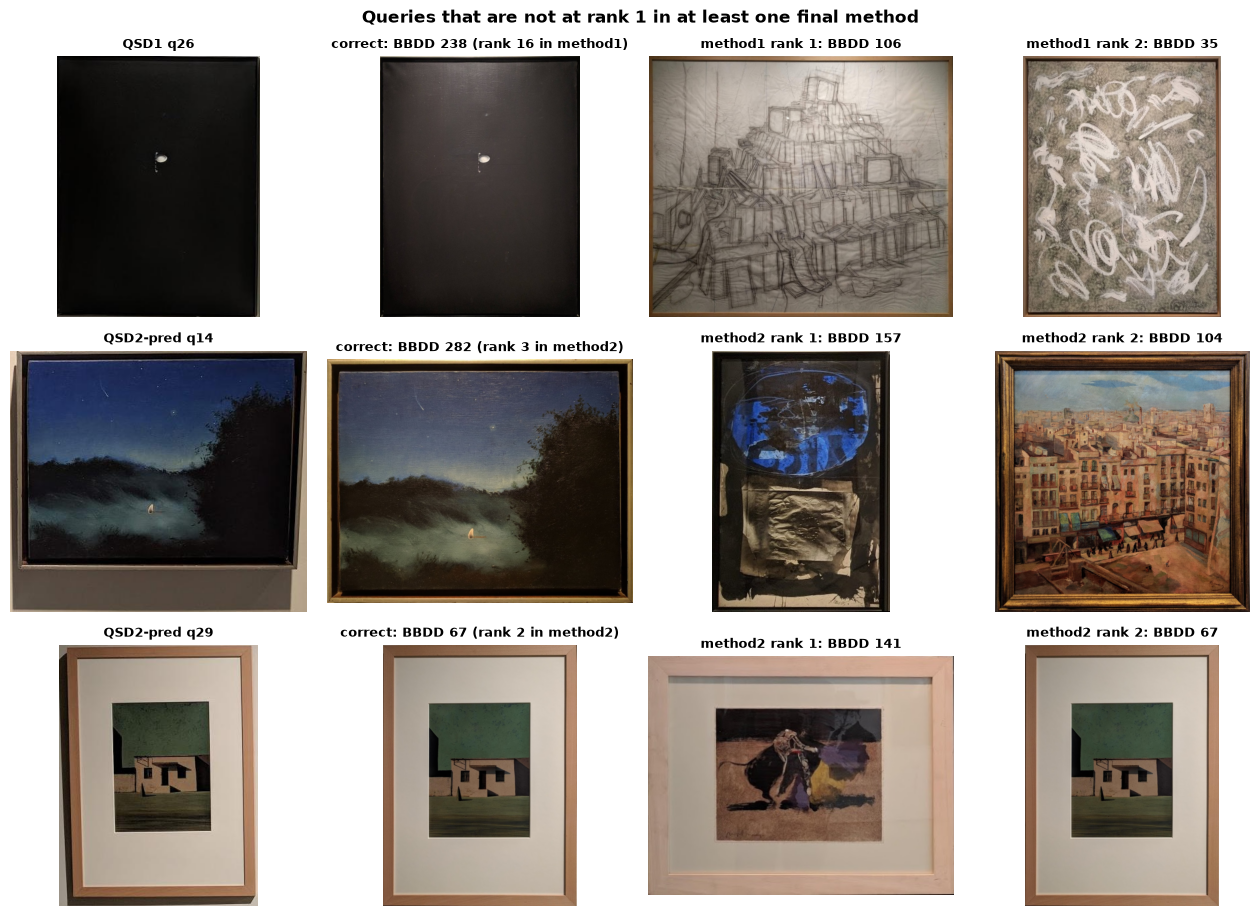

In [42]:
errs = []                                         # (set, query, first method where it is not at rank 1)
for s in ALL3:
    for i in range(30):
        bad = [k for k in FINAL if final_pos[(k, s)][i] > 1]
        if bad:
            errs.append((s, i, bad[0]))
fig, axes = plt.subplots(len(errs), 4, figsize=(13, 3.1 * len(errs)), squeeze=False)
for row, (s, i, key) in zip(axes, errs):
    imgs, gt = SETS[s]
    m = FINAL[key]
    order = rank(describe_final(imgs[i], m)[None], FINAL_DB[key], m["dist"])[0]
    p = [BBDD_IDS[j] for j in order].index(gt[i][0]) + 1
    tiles = [(imgs[i], f"{s} q{i}"), (BBDD[BBDD_IDS.index(gt[i][0])], f"correct: BBDD {gt[i][0]} (rank {p} in {key})")]
    tiles += [(BBDD[order[k]], f"{key} rank {k + 1}: BBDD {BBDD_IDS[order[k]]}") for k in range(2)]
    for ax, (img, title) in zip(row, tiles):
        ax.imshow(img[..., ::-1]); ax.set_title(title, fontsize=9); ax.axis("off")
plt.suptitle("Queries that are not at rank 1 in at least one final method", fontweight="bold"); plt.tight_layout(); savefig("final_errors"); plt.show()

**Error analysis**
- **QSD1 q26 (both methods):** an almost black painting. The illumination normalisation multiplies its channels by a very
  large factor, which amplifies the noise and the JPEG artefacts, and after that it looks like a grey drawing. In a
  preliminary test (not repeated in this notebook) we limited the gain of the normalisation, but the other queries got
  much worse (mean mAP@1 ≈ 0.95 → 0.83–0.93), so we keep the full normalisation.
- **QSD2-pred q10:** a black plastic sheet whose reflections change completely between the two photos (in the BBDD image a
  person is reflected); with our crop it is at rank 2.
- **QSD2-pred q14 and q29 (method 2 only):** small crop errors (a strip of wall and shadow below q14, the
  light passe-partout of q29 next to a light wall) shift the 5×5 block grid; the YCrCb pyramid of method 1, whose coarse
  levels tolerate these shifts, gets both right.

## 7. Task 6 – Blind test submission (QST1 and QST2)

- **QST1** (cropped paintings): descriptor of each query → top-10 BBDD ids.
- **QST2** (paintings with background): mask with M2 → crop the bounding box → descriptor → top-10. The masks are saved as
  `.png` (0 / 255) with the same name as the query.

The week-2 instructions only ask for **one method** (`method1`), so we submit **method1** (YCrCb 3D pyramid, the best one
on QSD2 with our masks). method2 stays in the notebook as the comparison; to also generate it, add `"method2"` to `SUBMIT`.

Output (to upload to the Drive):
```
results/QST1/method1/result.pkl
results/QST2/method1/result.pkl
results/QST2/method1/*.png        (the masks)
```
Each `result.pkl` is a list of lists of `int`: one list per query, in file order, with the 10 best BBDD ids.
If the test folders are not there yet, this cell does nothing.

In [43]:
def top_k(query_imgs, method_key, k=K):
    m = FINAL[method_key]
    Q = np.stack([describe_final(x, m) for x in query_imgs])
    return [[int(BBDD_IDS[j]) for j in o[:k]] for o in rank(Q, FINAL_DB[method_key], m["dist"])]


def check_format(preds, n):
    assert len(preds) == n and all(len(p) == K and all(type(i) is int for i in p) for p in preds)


def save_pkl(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump(obj, f)


SUBMIT = ["method1"]

# Sanity check of the whole pipeline on the development sets, exactly as it will run on the test sets
for key in FINAL:
    p1 = top_k(QSD1, key); p2 = top_k([resize_max(bbox_crop(im, m)) for im, m in zip(QSD2_FULL, QSD2_MASKS)], key)
    print(f"{key}: QSD1 mAP@1={mapk(GT1, p1, 1):.3f} mAP@5={mapk(GT1, p1, 5):.3f} | "
          f"QSD2 (our masks) mAP@1={mapk(GT2, p2, 1):.3f} mAP@5={mapk(GT2, p2, 5):.3f}")

if QST1_DIR is not None:
    qst1_ids, qst1 = load_folder(QST1_DIR)
    for key in SUBMIT:
        preds = top_k(qst1, key); check_format(preds, len(qst1))
        save_pkl(preds, RESULTS_DIR / "QST1" / key / "result.pkl")
    print(f"QST1: {len(qst1)} queries from {QST1_DIR} -> results/QST1/method1/result.pkl")
else:
    print("QST1 not found yet (put the folder qst1_w2 next to this notebook)")

if QST2_DIR is not None:
    qst2_paths = sorted(QST2_DIR.glob("*.jpg"), key=image_id)
    crops = []
    for p in qst2_paths:
        img = cv2.imread(str(p))
        mask = compute_mask(img)
        for key in SUBMIT:
            out = RESULTS_DIR / "QST2" / key / f"{p.stem}.png"
            out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), mask.astype(np.uint8) * 255)
        crops.append(resize_max(bbox_crop(img, mask)))
    for key in SUBMIT:
        preds = top_k(crops, key); check_format(preds, len(crops))
        save_pkl(preds, RESULTS_DIR / "QST2" / key / "result.pkl")
    print(f"QST2: {len(crops)} queries from {QST2_DIR} -> results/QST2/method1/result.pkl + masks")
else:
    print("QST2 not found yet (put the folder qst2_w2 next to this notebook)")

method1: QSD1 mAP@1=0.967 mAP@5=0.967 | QSD2 (our masks) mAP@1=1.000 mAP@5=1.000


method2: QSD1 mAP@1=0.967 mAP@5=0.967 | QSD2 (our masks) mAP@1=0.933 mAP@5=0.961
QST1 not found yet (put the folder qst1_w2 next to this notebook)
QST2 not found yet (put the folder qst2_w2 next to this notebook)


## 8. Summary (for the slides)

**Task 1 – descriptors**
- **3D joint histograms beat 1D and 2D** in every colour space (§3.2). 2D chroma-only histograms are the worst: after the
  illumination normalisation the brightness carries information.
- **Bin placement matters (answer to last year's feedback):** the chroma channels of Lab and YCrCb only use a narrow range
  of [0, 255]; with uniform bins most of them are empty (25 / 256 bins used in the example of §2.5). Adapting the edges to
  the real range of each channel improves Lab and YCrCb clearly and does nothing for HSV / RGB, which confirms the reason.
  Different bins per channel (fewer for the brightness) work well: (6, 12, 12), (8, 16, 16).
- **Blocks are the biggest gain:** from MRR ≈ 0.84–0.94 (1×1) to ≈ 0.97–0.99 (4×4 to 8×8). Curse of dimensionality: with
  more blocks, fewer bins are needed (HSV 4×4×4 in 5×5 blocks = 1600-D is as good as 12×8×8 in 4×4 blocks = 12 288-D).
- **Spatial pyramid:** finer levels weighted more is better or equal. On aligned crops it is only as good as the finest
  level alone, but **with imperfect crops (our masks) it is the most robust descriptor**, as the theory predicts.
- Distances: χ², Hellinger, JS ≈ best; Euclidean much worse.

**Task 2 – QSD1-W2 (same as QSD1-W1):** mAP@1 **0.90 → 0.97**, mAP@5 0.95 → 0.97. On QSD2-GT 0.57–0.70 → **1.00**: the
week-1 descriptors were over-fitted to QSD1, the new ones generalise. Only q26 (almost black painting) is still wrong.

**Task 3 – background removal with colour only:** per-image Gaussian model of the wall colour (robust mean / covariance of
a border strip, Lab) + Mahalanobis distance + automatic Otsu threshold + morphological post-processing (largest
component, hole filling, row / column filling).

**Task 4 – masks on QSD2:** **precision 0.953, recall 0.966, F1 0.956** (fixed colour threshold: F1 0.81–0.87; GMM: 0.93).
Remaining errors: cast shadows and a white painting on a white wall (not separable by colour).

**Task 5 – QSD2 retrieval with our masks:** the mask errors moved the block grid and the normalisation; a **5% inner
margin** fixes most of it (MRR 0.915 → 0.959 on average). Final: **method1 mAP@1 0.967 / mAP@5 0.983**, method2
0.933 / 0.961 (with perfect GT crops both reach 1.00).

**Task 6 – submission (one method, as asked):** method1 = YCrCb 3D 6×12×12 range bins, pyramid 1+2+4+8 (weights
1:2:4:8), Hellinger, 5% margin, and the QST2 masks with M2. method2 (HSV 3D 8×6×6, 5×5 blocks) is kept as the comparison.
The same pipeline is in `run_w2.py`.

| | QSD1 mAP@1 / @5 | QSD2-GT mAP@1 / @5 | QSD2 (our masks) mAP@1 / @5 | masks P / R / F1 |
|---|---|---|---|---|
| W1 method 1 (HSV 1D) | 0.900 / 0.950 | 0.567 / 0.638 | 0.500 / 0.578 | – |
| **W2 method1** (YCrCb 3D pyramid) | **0.967 / 0.967** | **1.000 / 1.000** | **0.967 / 0.983** | 0.953 / 0.966 / 0.956 |
| W2 method2 (HSV 3D blocks, not submitted) | **0.967 / 0.967** | **1.000 / 1.000** | 0.933 / 0.961 | 0.953 / 0.966 / 0.956 |